
# Can Textual Similarity Predict Character Interactions in Game of Thrones?

## 1. Introduction

This project investigates whether textual similarity between character biographies in the Game of Thrones Wiki of Westeros reflects interactions between characters in the HBO television series.

We combine two datasets:

1. Character interaction networks from Andrew Beveridge's Game of Thrones dataset.
2. Character biographies collected using the Wiki of Westeros MediaWiki API.

The main research question is:

**To what extent does textual similarity between Game of Thrones character biographies predict their interactions in the television series?**

We first characterize the interaction network using network science techniques. We then apply NLP methods, including TF-IDF and cosine similarity, to character biographies. Finally, we compare the textual similarities against observed character interactions and evaluate the results using appropriate baselines.


In [1]:

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "mathbeveridge/gameofthrones/master/data"
)

season_data = {}

for season in range(1, 9):
    url = f"{BASE_URL}/got-s{season}-edges.csv"

    df = pd.read_csv(url)
    df["Season"] = season

    season_data[season] = df

    print(
        f"Season {season}: "
        f"{len(df)} interactions (edge records)"
    )


Season 1: 549 interactions (edge records)
Season 2: 486 interactions (edge records)
Season 3: 504 interactions (edge records)
Season 4: 667 interactions (edge records)
Season 5: 397 interactions (edge records)
Season 6: 542 interactions (edge records)
Season 7: 412 interactions (edge records)
Season 8: 553 interactions (edge records)


In [2]:

# Inspect the first few rows
display(season_data[1].head())

# Check the column names
print("Columns:", season_data[1].columns.tolist())

# Check for missing values
print("\nMissing values:")
print(season_data[1].isna().sum())


,Source,Target,Weight,Season
0,NED,ROBERT,192,1
1,DAENERYS,JORAH,154,1
2,JON,SAM,121,1
3,LITTLEFINGER,NED,107,1
4,NED,VARYS,96,1


Columns: ['Source', 'Target', 'Weight', 'Season']

Missing values:
Source    0
Target    0
Weight    0
Season    0
dtype: int64


In [3]:

# Combine all seasons
all_edges = pd.concat(
    season_data.values(),
    ignore_index=True
)

# Normalize undirected pairs so A-B and B-A are identical
pairs = all_edges[["Source", "Target"]].apply(
    lambda row: sorted([row["Source"], row["Target"]]),
    axis=1,
    result_type="expand"
)

all_edges["Source"] = pairs[0]
all_edges["Target"] = pairs[1]

# Aggregate interaction weights across seasons
combined_edges = (
    all_edges
    .groupby(["Source", "Target"], as_index=False)
    .agg(
        Weight=("Weight", "sum"),
        Seasons=("Season", "nunique")
    )
)

print("Total seasonal edge records:", len(all_edges))
print("Unique character pairs:", len(combined_edges))

display(combined_edges.head())


Total seasonal edge records: 4110
Unique character pairs: 2637


,Source,Target,Weight,Seasons
0,ADDAM_MARBRAND,KEVAN,3,1
1,ADDAM_MARBRAND,LEO_LEFFORD,3,1
2,ADDAM_MARBRAND,TYWIN,2,1
3,ADRACK_HUMBLE,RALF,2,1
4,ADRACK_HUMBLE,THEON,4,1


In [4]:

G = nx.from_pandas_edgelist(
    combined_edges,
    source="Source",
    target="Target",
    edge_attr=["Weight", "Seasons"],
    create_using=nx.Graph()
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Directed:", G.is_directed())
print("Density:", nx.density(G))
print("Connected components:",
      nx.number_connected_components(G))


Number of nodes: 406
Number of edges: 2637
Directed: False
Density: 0.032074438970990694
Connected components: 2



## 2. Network Visualization

We visualize the aggregated Game of Thrones interaction network using NetworkX.

Each node represents a character, and each edge represents an interaction between two characters.

Node size is proportional to degree, so characters who interact with more distinct characters appear larger.

The visualization uses a spring layout, which places densely connected groups of characters closer together.

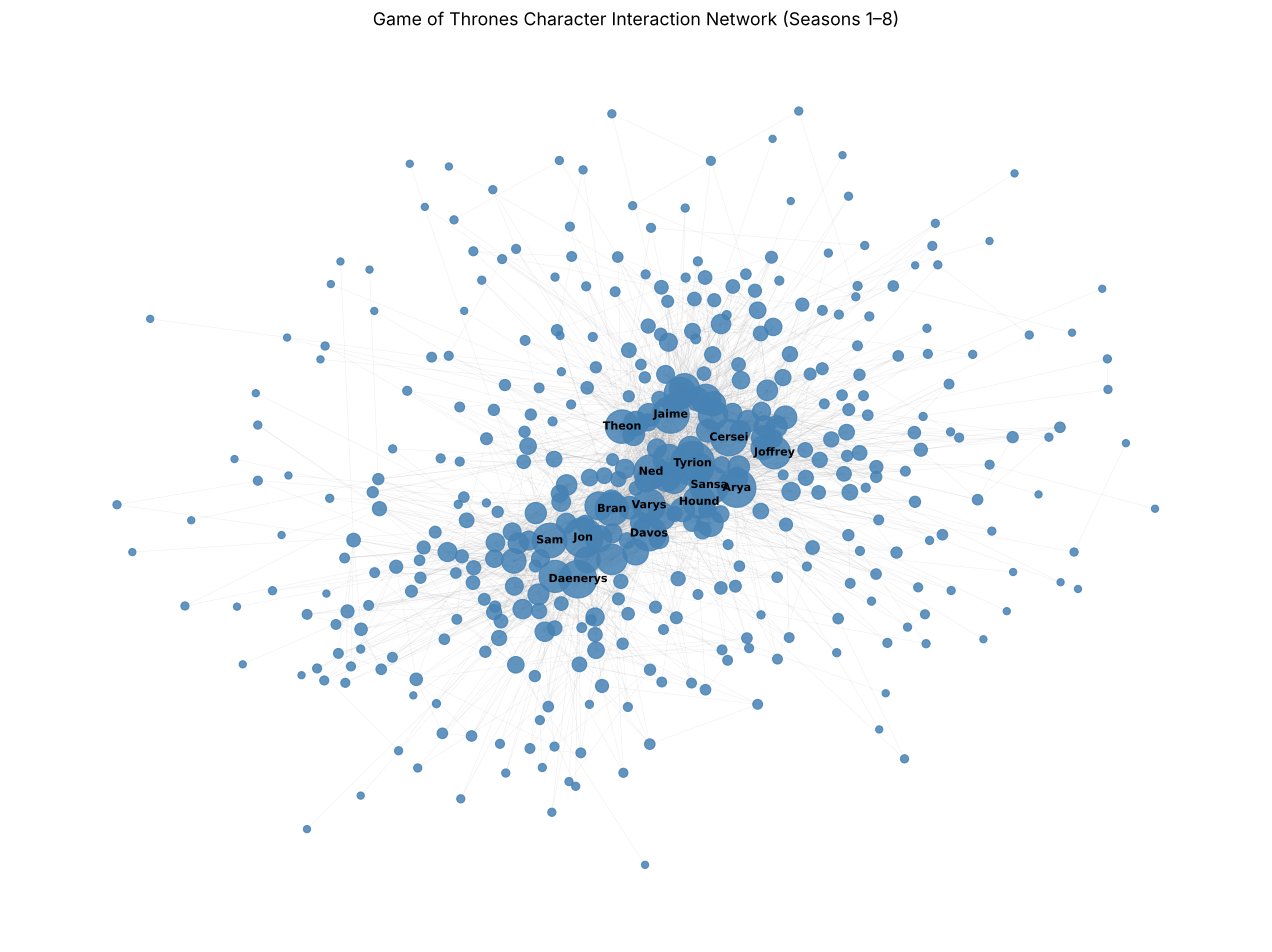

In [5]:
import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(16, 12))

# Position nodes using a force-directed layout
pos = nx.spring_layout(G, seed=42, k=0.3)

# Calculate degree for each character
degrees = dict(G.degree())

# Scale node sizes by degree
node_sizes = [
    30 + degrees[node] * 12
    for node in G.nodes()
]

# Draw edges
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.12,
    width=0.5,
    edge_color="gray"
)

# Draw nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color="steelblue",
    alpha=0.85
)

# Label only the 15 most connected characters
top_characters = sorted(
    degrees,
    key=degrees.get,
    reverse=True
)[:15]

labels = {
    node: node.replace("_", " ").title()
    for node in top_characters
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=10,
    font_weight="bold"
)

plt.title(
    "Game of Thrones Character Interaction Network (Seasons 1–8)",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()
plt.show()



## 3. Degree Distribution

The degree of a node represents the number of distinct characters with whom a character interacts.

We analyze the degree distribution to understand how connectivity varies across the Game of Thrones network.

This is important for our research question because highly connected characters may be more likely to appear in predicted relationships, independently of textual similarity.


,Character,Degree
35,TYRION,128
24,JON,105
33,SANSA,101
9,ARYA,97
10,DAENERYS,93
22,JAIME,90
21,CERSEI,86
55,SAM,78
26,NED,78
11,DAVOS,78


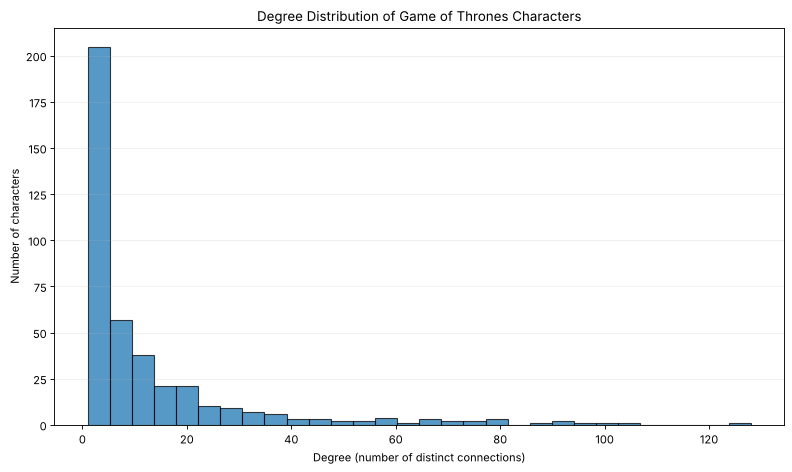

Average degree: 12.990147783251231
Median degree: 5.0
Maximum degree: 128


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate degree for each character
degrees = dict(G.degree())

degree_df = pd.DataFrame({
    "Character": list(degrees.keys()),
    "Degree": list(degrees.values())
}).sort_values("Degree", ascending=False)

# Display the 15 most connected characters
display(degree_df.head(15))

# Plot the degree distribution
plt.figure(figsize=(10, 6))

plt.hist(
    degree_df["Degree"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.xlabel("Degree (number of distinct connections)")
plt.ylabel("Number of characters")
plt.title("Degree Distribution of Game of Thrones Characters")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("Average degree:", np.mean(list(degrees.values())))
print("Median degree:", np.median(list(degrees.values())))
print("Maximum degree:", max(degrees.values()))



### Interpretation

The Game of Thrones interaction network exhibits a strongly right-skewed degree distribution. Most characters interact with relatively few others, while a small number of highly connected characters have substantially more connections.

The average degree is approximately 12.99, compared with a median of 5 and a maximum of 128. This difference indicates considerable heterogeneity in character connectivity.

This finding is relevant to our research question because highly connected characters have more observed interactions, independently of their textual descriptions. Consequently, we will compare text-based interaction predictions against a degree-based baseline to assess whether textual similarity provides additional predictive information.

Although the distribution has a long right tail, we do not assume that it follows a power law without further statistical testing.



## 4. Centrality Analysis

Centrality measures identify different forms of structural importance in a network.

We compare three measures:

- **Degree:** The number of distinct characters connected to each character.
- **Betweenness centrality:** The extent to which a character lies on shortest paths between other characters.
- **PageRank:** A measure of importance based on connections to other important characters.

We initially use the unweighted graph to compare structural positions. Interaction weights are retained for subsequent analyses.

These measures provide context for understanding which characters occupy important positions in the Game of Thrones interaction network.


In [7]:

# Degree
degree = dict(G.degree())

# Betweenness centrality
betweenness = nx.betweenness_centrality(
    G,
    normalized=True,
    weight=None
)

# PageRank
pagerank = nx.pagerank(
    G,
    alpha=0.85,
    weight=None
)

# Combine results
centrality_df = pd.DataFrame({
    "Character": list(G.nodes()),
    "Degree": [degree[n] for n in G.nodes()],
    "Betweenness": [betweenness[n] for n in G.nodes()],
    "PageRank": [pagerank[n] for n in G.nodes()]
})

# Top 15 by degree
display(
    centrality_df
    .sort_values("Degree", ascending=False)
    .head(15)
    .round(4)
)


,Character,Degree,Betweenness,PageRank
35,TYRION,128,0.1319,0.0221
24,JON,105,0.0956,0.0174
33,SANSA,101,0.0569,0.0158
9,ARYA,97,0.1018,0.0181
10,DAENERYS,93,0.1122,0.0178
22,JAIME,90,0.0546,0.0145
21,CERSEI,86,0.0448,0.0138
55,SAM,78,0.0568,0.0130
26,NED,78,0.0448,0.0128
11,DAVOS,78,0.0467,0.0128


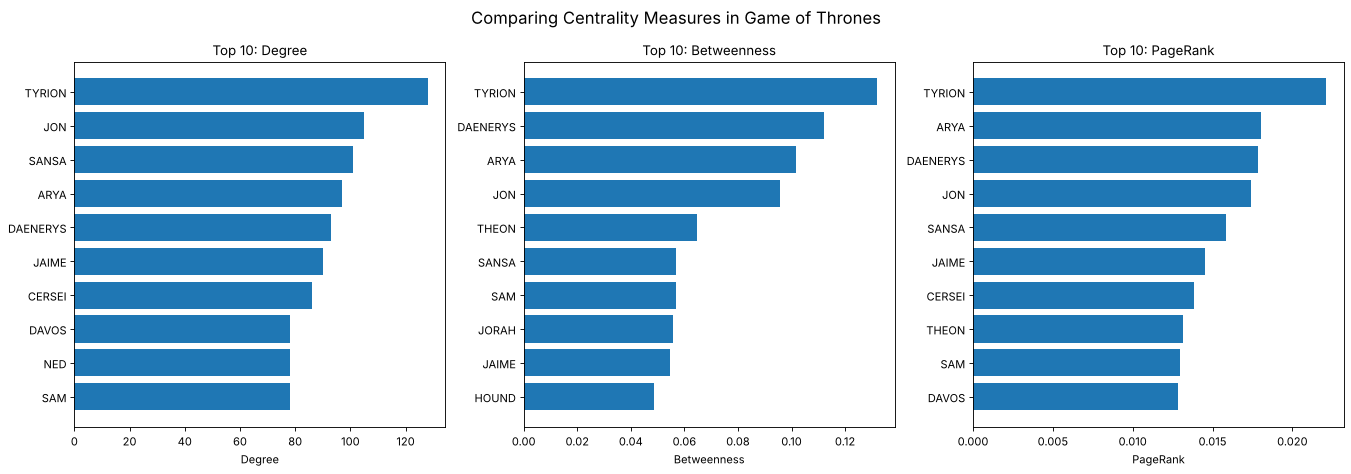

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

metrics = ["Degree", "Betweenness", "PageRank"]

for ax, metric in zip(axes, metrics):
    top = centrality_df.nlargest(10, metric)

    ax.barh(
        top["Character"][::-1],
        top[metric][::-1]
    )

    ax.set_title(f"Top 10: {metric}")
    ax.set_xlabel(metric)

plt.suptitle(
    "Comparing Centrality Measures in Game of Thrones",
    fontsize=15
)

plt.tight_layout()
plt.show()



### Interpretation

The centrality analysis reveals differences in the structural roles of Game of Thrones characters.

Tyrion Lannister ranks highest across all three measures, with a degree of 128, betweenness centrality of approximately 0.132, and PageRank of approximately 0.022. This indicates that Tyrion is highly connected and occupies a prominent structural position in the interaction network.

However, the rankings differ across measures. For example, Daenerys ranks fifth in degree but second in betweenness centrality, suggesting that she plays an important role in connecting otherwise separated parts of the network.

These results illustrate that centrality is multidimensional: having many connections does not necessarily imply occupying the strongest bridging position.

For our research question, degree is particularly relevant because highly connected characters have more observed interactions. We will therefore use network connectivity as a baseline when evaluating whether textual similarity predicts character interactions.


## 5. Community Detection

Community detection identifies groups of nodes that are more densely connected internally than externally.

We apply the Louvain algorithm to the Game of Thrones interaction network to identify communities based on character interactions.

We use the weighted network, where edge weights represent interaction strength across all eight seasons.

We also calculate modularity to evaluate how strongly the detected communities partition the network.

Finally, we visualize the network with nodes colored according to their community membership.


In [9]:

import networkx as nx
import pandas as pd

# Detect communities using weighted Louvain
communities = nx.community.louvain_communities(
    G,
    weight="Weight",
    resolution=1,
    seed=42
)

# Calculate modularity
modularity = nx.community.modularity(
    G,
    communities,
    weight="Weight"
)

print("Number of communities:", len(communities))
print("Modularity:", round(modularity, 4))

# Assign each character to a community
community_map = {
    node: i
    for i, community in enumerate(communities)
    for node in community
}

# Summarize community sizes
community_sizes = pd.DataFrame({
    "Community": range(len(communities)),
    "Size": [len(c) for c in communities]
}).sort_values("Size", ascending=False)

display(community_sizes)

# Show the most connected characters in each community
for i, community in enumerate(communities):
    top_nodes = sorted(
        community,
        key=lambda n: G.degree(n),
        reverse=True
    )[:8]

    print(f"Community {i} ({len(community)} characters):")
    print(", ".join(top_nodes))
    print()


Number of communities: 8
Modularity: 0.4701


,Community,Size
6,6,104
0,0,85
4,4,74
1,1,53
3,3,44
2,2,38
5,5,5
7,7,3


Community 0 (85 characters):
JON, DAVOS, SAM, TORMUND, STANNIS, EDDISON_TOLLETT, MELISANDRE, GILLY

Community 1 (53 characters):
DAENERYS, JORAH, GREY_WORM, MISSANDEI, QHONO, BARRISTAN, DROGO, DAARIO

Community 2 (38 characters):
SANSA, NED, LITTLEFINGER, ROBERT, YOHN_ROYCE, MAESTER_WOLKAN, ROBIN, AERYS

Community 3 (44 characters):
ARYA, HOUND, GENDRY, BERIC, YOREN, LADY_CRANE, JAQEN, HOT_PIE

Community 4 (74 characters):
THEON, BRAN, ROBB, CATELYN, YARA, EDMURE, ROOSE_BOLTON, RAMSAY

Community 5 (5 characters):
JOFFREY_DWARF, ROBB_DWARF, RENLY_DWARF, BALON_DWARF, STANNIS_DWARF

Community 6 (104 characters):
TYRION, JAIME, CERSEI, VARYS, JOFFREY, BRONN, BRIENNE, TYWIN

Community 7 (3 characters):
MULLY, BLACK_JACK, KEGS



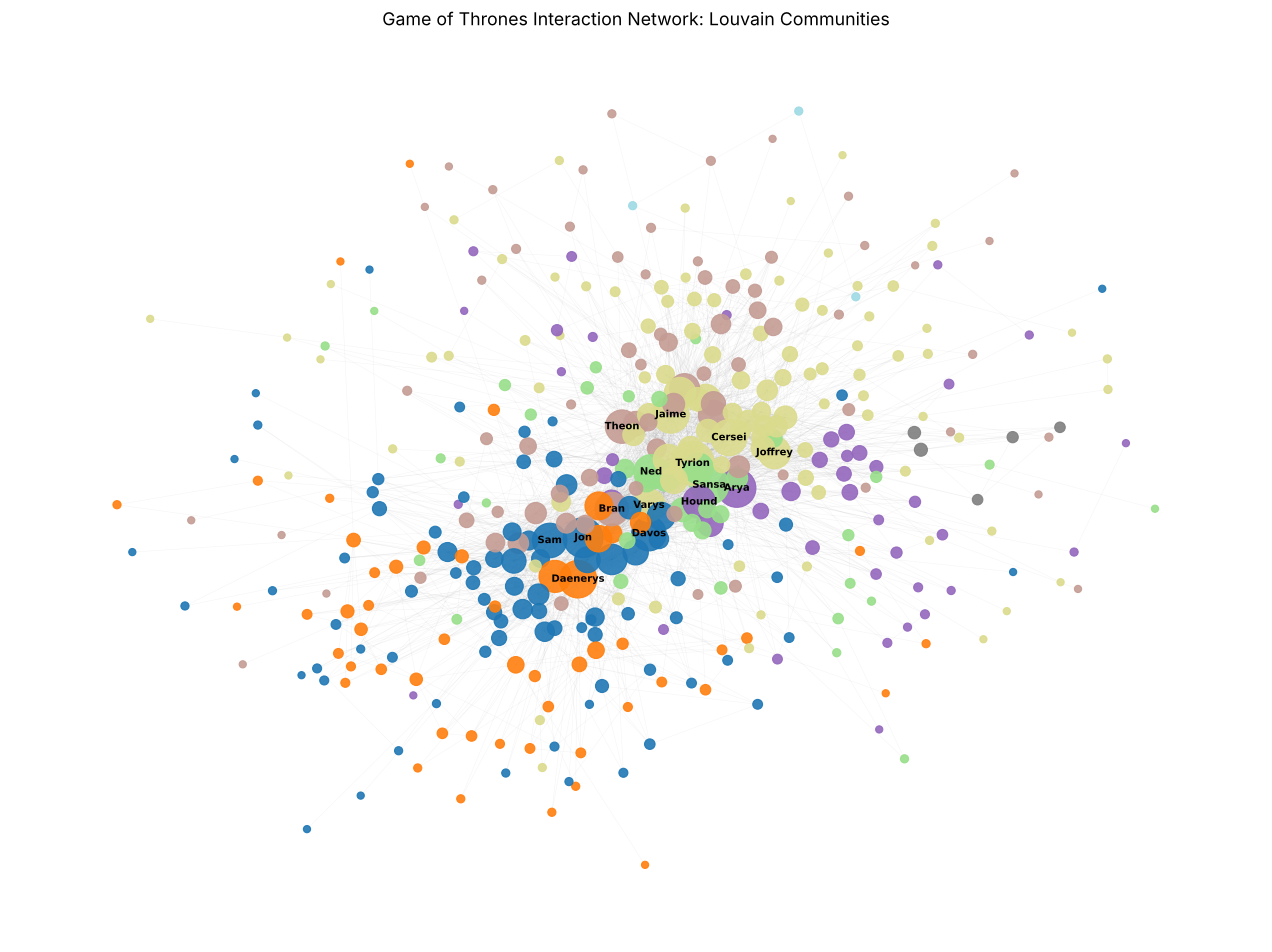

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

# Reuse the previous spring layout
# so we can compare the two visualizations

node_colors = [
    community_map[node]
    for node in G.nodes()
]

node_sizes = [
    30 + G.degree(node) * 12
    for node in G.nodes()
]

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.08,
    width=0.5,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# Label the 15 highest-degree characters
labels = {
    node: node.title()
    for node in sorted(
        G.nodes(),
        key=lambda n: G.degree(n),
        reverse=True
    )[:15]
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=9,
    font_weight="bold"
)

plt.title(
    "Game of Thrones Interaction Network: Louvain Communities",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()
plt.show()



### Interpretation

The Louvain algorithm identified eight communities in the aggregated Game of Thrones interaction network.

Several communities correspond to recognizable narrative groups. For example, one community contains Jon Snow, Samwell Tarly, Davos Seaworth, and Tormund, while another contains Daenerys Targaryen, Jorah Mormont, Grey Worm, and Missandei.

Other communities are associated with Arya's travels, Northern storylines, and political interactions around King's Landing.

These results suggest that the interaction network contains meaningful narrative organization that can be identified using network structure alone.

However, community assignments should not be interpreted as exact political factions or geographical divisions. Characters may participate in multiple storylines, while Louvain assigns each character to a single community.

This analysis also motivates a secondary NLP question: are biographies of characters belonging to the same interaction community more textually similar than biographies of characters belonging to different communities?



## 6. Null Model Comparison

To evaluate whether the observed community structure is stronger than expected by chance, we compare the Game of Thrones interaction network against randomized networks.

We use degree-preserving edge rewiring, which changes the connections between characters while preserving the degree of every node.

For a consistent comparison, we perform community detection and calculate modularity on unweighted versions of both the observed and randomized networks.

We compare the observed modularity with the distribution of modularity values obtained from randomized networks.

This allows us to investigate whether the network exhibits stronger community structure than expected from its degree sequence alone.


In [11]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Observed unweighted community structure
observed_communities = nx.community.louvain_communities(
    G,
    weight=None,
    seed=42
)

observed_modularity = nx.community.modularity(
    G,
    observed_communities,
    weight=None
)

print("Observed unweighted modularity:",
      round(observed_modularity, 4))

# Generate degree-preserving randomized networks
n_randomizations = 100
random_modularities = []

for i in range(n_randomizations):

    G_random = G.copy()

    # Randomly rewire edges while preserving node degrees
    nx.double_edge_swap(
        G_random,
        nswap=G.number_of_edges() * 3,
        max_tries=G.number_of_edges() * 50,
        seed=42 + i
    )

    # Detect communities in the randomized graph
    random_communities = nx.community.louvain_communities(
        G_random,
        weight=None,
        seed=42
    )

    random_modularity = nx.community.modularity(
        G_random,
        random_communities,
        weight=None
    )

    random_modularities.append(random_modularity)

print("Mean random modularity:",
      round(np.mean(random_modularities), 4))

print("Standard deviation:",
      round(np.std(random_modularities), 4))


Observed unweighted modularity: 0.3991
Mean random modularity: 0.1923
Standard deviation: 0.0029


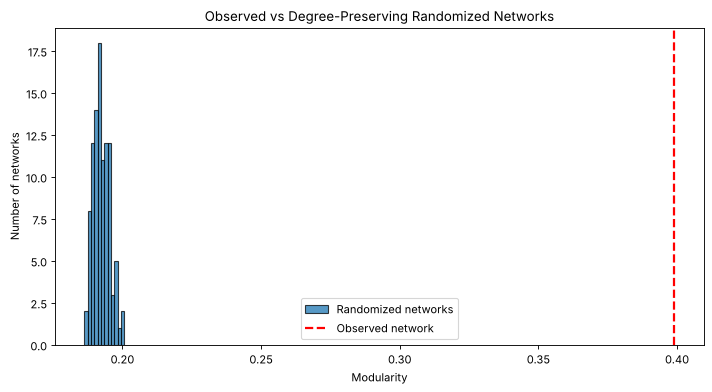

Empirical p-value: 0.0099


In [12]:

plt.figure(figsize=(9, 5))

plt.hist(
    random_modularities,
    bins=12,
    edgecolor="black",
    alpha=0.75,
    label="Randomized networks"
)

plt.axvline(
    observed_modularity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Observed network"
)

plt.xlabel("Modularity")
plt.ylabel("Number of networks")
plt.title("Observed vs Degree-Preserving Randomized Networks")
plt.legend()
plt.tight_layout()
plt.show()

# Empirical one-sided p-value
p_value = (
    1 + sum(
        q >= observed_modularity
        for q in random_modularities
    )
) / (n_randomizations + 1)

print("Empirical p-value:", round(p_value, 4))



### Interpretation of the Null Model

The observed Game of Thrones interaction network has an unweighted modularity of approximately 0.3991. In comparison, 100 degree-preserving randomized networks have a mean modularity of 0.1922, with a standard deviation of 0.0032.

The observed modularity is approximately 2.08 times the randomized mean, indicating substantially stronger community structure than expected from the degree distribution alone.

 None of the 100 randomized networks reached the observed modularity (empirical one-sided p = 0.0099, the smallest value attainable with 100 randomizations).

These results suggest that character interactions are organized into meaningful communities rather than being explained solely by differences in character connectivity. This is consistent with the existence of distinct narrative groups and storylines within Game of Thrones.

However, the null model preserves node degrees but not necessarily connected components or interaction weights. Therefore, the findings should be interpreted relative to this particular randomized-network model.

The comparison uses unweighted modularity for both the observed and randomized networks.


## 7. Summary of Network Analysis

We constructed an aggregated, undirected interaction network using Game of Thrones character interactions across all eight seasons.

The network contains 406 characters and 2,637 unique interaction edges, with a density of approximately 0.0321.

The degree distribution is strongly right-skewed, with an average degree of 12.99 and a median degree of 5. This indicates that most characters have relatively few connections, while a small number of characters interact with many others.

Centrality analysis identified Tyrion Lannister as the most prominent character across degree, betweenness centrality, and PageRank. Other characters, including Daenerys Targaryen and Arya Stark, occupy important bridging positions in the network.

Weighted Louvain community detection identified eight communities, several of which correspond to recognizable narrative groups and storylines.

Finally, a degree-preserving null-model experiment showed that the observed unweighted modularity (0.3991) was substantially higher than the average modularity of randomized networks (0.1922).

Together, these results show that the interaction network is heterogeneous and contains meaningful community structure.

### Connection to the Research Question

The network analysis establishes the observed character interactions against which textual similarity will be evaluated.

The unequal degree distribution motivates the use of degree-based prediction baselines, while the detected communities provide an opportunity to investigate whether characters within the same interaction community have more similar biographies.

In the next section, we will collect character biographies from the Wiki of Westeros, apply NLP techniques, and test whether textual similarity can predict observed character interactions.



## 8. Character Biography Collection

We collect character biographies from the Wiki of Westeros (Game of Thrones Fandom) to investigate whether textual similarity between character descriptions is associated with their observed interactions.

The interaction network contains 406 characters. Our objective is to retrieve usable textual descriptions for as many of these characters as possible.

We first test the data collection procedure on a small sample before extending it to the complete network.

The collected texts will subsequently be cleaned, transformed into TF-IDF vectors, and compared using cosine similarity.


### 8.1. Loading the Manually Curated Character Mappings

To improve the accuracy of biography collection, we use a
manually curated Excel file containing character identifiers,
corresponding Game of Thrones Fandom Wiki article titles,
and article URLs.

This avoids relying on automatic name matching, which can
produce incorrect results for characters with ambiguous
names, aliases, or alternative spellings.

We first load the mappings and verify their consistency
with the interaction network before retrieving biographies.

In [13]:
import pandas as pd

# Load manually curated Wiki mappings
df_mapping = pd.read_excel("Characters.xlsx")

# Standardize column names
df_mapping = df_mapping.rename(columns={
    "Character": "Network_ID",
    "Article name": "Wiki_Title",
    "URL": "Wiki_URL"
})

# Clean string fields
for col in ["Network_ID", "Wiki_Title", "Wiki_URL"]:
    df_mapping[col] = df_mapping[col].astype("string").str.strip()

# Characters present in the network
network_characters = (
    set(combined_edges["Source"]) |
    set(combined_edges["Target"])
)

# Validate mappings
df_mapping["In_Network"] = (
    df_mapping["Network_ID"].isin(network_characters)
)

df_mapping["Valid_URL_Format"] = (
    df_mapping["Wiki_URL"]
    .str.startswith("https://gameofthrones.fandom.com/wiki/")
    .fillna(False)
)

print("Total network characters:", len(network_characters))
print("Mappings in Excel:", len(df_mapping))
print("Mappings matching network IDs:", df_mapping["In_Network"].sum())
print("URLs with expected format:", df_mapping["Valid_URL_Format"].sum())

print(
    "Mapping coverage:",
    f"{df_mapping['In_Network'].sum() / len(network_characters):.1%}"
)

print("\nCharacters with no manual mapping:")
missing_characters = sorted(
    network_characters - set(df_mapping["Network_ID"])
)
print(len(missing_characters))

print("\nSample mappings:")
display(df_mapping.head(10))

print("\nMappings requiring inspection:")
display(
    df_mapping[
        ~df_mapping["In_Network"] |
        ~df_mapping["Valid_URL_Format"]
    ]
)

Total network characters: 406
Mappings in Excel: 330
Mappings matching network IDs: 330
URLs with expected format: 330
Mapping coverage: 81.3%

Characters with no manual mapping:
76

Sample mappings:


,Network_ID,Wiki_Title,Wiki_URL,In_Network,Valid_URL_Format
0,ADDAM_MARBRAND,Addam Marbrand,https://gameofthrones.fandom.com/wiki/Addam_Marbrand,True,True
1,ADRACK_HUMBLE,Adrack Humble,https://gameofthrones.fandom.com/wiki/Adrack_Humble,True,True
2,AEGON,Aegon I Targaryen,https://gameofthrones.fandom.com/wiki/Aegon_I_Targaryen,True,True
3,AERON,Aeron Greyjoy,https://gameofthrones.fandom.com/wiki/Aeron_Greyjoy,True,True
4,AERYS,Aerys II Targaryen,https://gameofthrones.fandom.com/wiki/Aerys_II_Targaryen,True,True
5,ALANNA,Alanna,https://gameofthrones.fandom.com/wiki/Alanna,True,True
6,ALLISER_THORNE,Alliser Thorne,https://gameofthrones.fandom.com/wiki/Alliser_Thorne,True,True
7,ALTON,Alton Lannister,https://gameofthrones.fandom.com/wiki/Alton_Lannister,True,True
8,ALYS,Alys Karstark,https://gameofthrones.fandom.com/wiki/Alys_Karstark,True,True
9,AMORY,Amory Lorch,https://gameofthrones.fandom.com/wiki/Amory_Lorch,True,True



Mappings requiring inspection:


,Network_ID,Wiki_Title,Wiki_URL,In_Network,Valid_URL_Format


### 8.2. Testing Biography Extraction

We use the manually curated Wiki URLs to retrieve character
biographies from the Game of Thrones Fandom Wiki.

Before collecting the full dataset, we test the extraction
procedure on a small sample of characters.

We use the MediaWiki API to request the plain-text content
of each article, avoiding unnecessary HTML elements such
as navigation menus and website advertisements.

The objective is to obtain comparable textual representations
of characters for subsequent TF-IDF and cosine similarity analysis.

In [14]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urlparse, unquote

API_URL = "https://gameofthrones.fandom.com/api.php"

def extract_wiki_text(url):
    title = unquote(
        urlparse(url).path.split("/wiki/")[-1]
    ).replace("_", " ")

    params = {
        "action": "parse",
        "page": title,
        "prop": "text",
        "format": "json"
    }

    try:
        response = requests.get(
            API_URL,
            params=params,
            headers={
                "User-Agent": "GoTSocialGraphsStudentProject/1.0"
            },
            timeout=30
        )
        response.raise_for_status()

        data = response.json()

        if "error" in data:
            print(f"API error for {title}: {data['error']}")
            return None

        html = data["parse"]["text"]["*"]
        soup = BeautifulSoup(html, "html.parser")

        for element in soup.select(
            "script, style, table, aside, "
            ".toc, .reference, .reflist, "
            ".navbox, .portable-infobox"
        ):
            element.decompose()

        text = soup.get_text(
            separator=" ",
            strip=True
        )

        return text if text else None

    except (requests.RequestException, ValueError, KeyError) as e:
        print(f"Error retrieving {title}: {e}")
        return None


# Test only three characters first
test_mapping = df_mapping[
    df_mapping["Network_ID"].isin([
        "ARYA", "CERSEI", "TYRION"
    ])
]

for _, row in test_mapping.iterrows():
    text = extract_wiki_text(row["Wiki_URL"])

    print(f"\n{row['Wiki_Title']}")
    print("Words:", len(text.split()) if text else 0)
    print("Preview:", text[:300] if text else "No text retrieved")


Arya Stark
Words: 23357
Preview: " A girl is Arya Stark of Winterfell, and I'm going home. " ―Arya Stark re-asserts her identity to Jaqen H'ghar [src] Arya Stark is the third child and second daughter of Lord Eddard Stark and his wife, Lady Catelyn Stark . She is the sister of the incumbent Westerosi monarchs, Sansa , Queen in the 

Cersei Lannister
Words: 21933
Preview: " When you play the game of thrones, you win or you die. There is no middle ground. " ―Cersei Lannister to Eddard Stark [src] Queen Cersei I Lannister was the twentieth ruler of the Seven Kingdoms and the widow of King Robert Baratheon . She was the daughter of Lord Tywin Lannister , twin sister of 

Tyrion Lannister
Words: 27551
Preview: Tyrion Lannister : " I'm guilty of a far more monstrous crime: I'm guilty of being a dwarf! " Tywin Lannister : " You are not on trial for being a dwarf. " Tyrion Lannister : " Oh, yes I am! I've been on trial for that my entire life! " — Tyrion at his trial, falsely accused of killi

### 8.3. Extracting Biographical and Storyline Sections

To obtain comparable textual representations of characters,
we restrict extraction to biographical content from the
Game of Thrones Fandom Wiki.

We include character background and storyline descriptions
from the television series, while excluding unrelated
sections such as quotations, production information,
book-specific material, galleries, and references.

Because Wiki articles differ in structure, relevant sections
are identified dynamically using their headings rather
than fixed section numbers.

This approach aims to reduce irrelevant textual information
before TF-IDF vectorization.

In [15]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urlparse, unquote

API_URL = "https://gameofthrones.fandom.com/api.php"

def extract_biography(url):

    title = unquote(
        urlparse(url).path.split("/wiki/")[-1]
    ).replace("_", " ")

    try:
        # Step 1: Find the Biography section
        response = requests.get(
            API_URL,
            params={
                "action": "parse",
                "page": title,
                "prop": "sections",
                "format": "json"
            },
            timeout=30
        )
        response.raise_for_status()

        data = response.json()

        if "error" in data:
            return None

        biography_section = None

        for section in data["parse"]["sections"]:

            heading = BeautifulSoup(
                section["line"], "html.parser"
            ).get_text(" ", strip=True).lower()

            if heading == "biography":
                biography_section = section["index"]
                break

        if biography_section is None:
            return None

        # Step 2: Retrieve the Biography section only
        response = requests.get(
            API_URL,
            params={
                "action": "parse",
                "page": title,
                "prop": "text",
                "section": biography_section,
                "format": "json"
            },
            timeout=30
        )
        response.raise_for_status()

        data = response.json()

        if "error" in data:
            return None

        html = data["parse"]["text"]["*"]
        soup = BeautifulSoup(html, "html.parser")

        # Remove unwanted content
        for element in soup.select(
            "script, style, table, aside, "
            ".toc, .toccolours, #toc, "
            ".reference, .reflist, "
            ".navbox, .portable-infobox"
        ):
            element.decompose()

        text = soup.get_text(" ", strip=True)

        return text if text else None

    except (requests.RequestException, ValueError, KeyError) as e:
        print(f"Error retrieving {title}: {e}")
        return None


# Test on three characters
test_mapping = df_mapping[
    df_mapping["Network_ID"].isin([
        "ARYA", "CERSEI", "TYRION"
    ])
]

for _, row in test_mapping.iterrows():

    text = extract_biography(row["Wiki_URL"])

    print(f"\n{row['Wiki_Title']}")
    print("Words:", len(text.split()) if text else 0)
    print("Preview:", text[:300] if text else "No text retrieved")


Arya Stark
Words: 14503
Preview: Biography [ ] Background [ ] Arya Stark is the youngest daughter and third child of Lady Catelyn and Lord Ned Stark. Arya was born and raised at Winterfell . She has an older sister, Sansa , an older brother Robb , two younger brothers Bran and Rickon Stark, and a "bastard half-brother" Jon Snow . A

Cersei Lannister
Words: 13751
Preview: Biography [ ] Background [ ] Cersei was the only daughter and eldest child of Lord Tywin and Lady Joanna Lannister . Cersei was the elder twin of Jaime Lannister and the elder sister of Tyrion Lannister . She was raised in the family seat of Casterly Rock . She was known for her great beauty as a yo

Tyrion Lannister
Words: 18649
Preview: Biography [ ] Background [ ] " You are an ill-made, spiteful little creature full of envy, lust, and low cunning. Men's laws give you the right to bear my name and display my colors since I cannot prove that you are not mine. And to teach me humility, the gods have condemned me to wa

### 8.4. Collecting All Character Biographies

After validating the extraction method, we collect the
biographical text of characters using the manually curated
Game of Thrones Fandom Wiki URLs.

We extract the Biography section, including its background
and storyline subsections, while excluding unrelated
sections such as quotations, production information,
and references.

For each character, we record its network identifier,
Wiki article title, article URL, extracted text, and word count.

The resulting dataset is saved locally to support
reproducibility and subsequent text analysis.

In [16]:
import pandas as pd
import time
from pathlib import Path

output_file = Path("got_character_biographies_only.csv")

# Load previously saved results, if available
if output_file.exists():
    df_biographies = pd.read_csv(output_file)
    print("Loaded existing biography dataset.")
else:
    df_biographies = pd.DataFrame(columns=[
        "Network_ID",
        "Wiki_Title",
        "Wiki_URL",
        "Text",
        "Words"
    ])

# Track processed characters
processed_ids = set(df_biographies["Network_ID"])

new_results = []

for _, row in df_mapping.iterrows():

    character = row["Network_ID"]

    if character in processed_ids:
        continue

    text = extract_biography(row["Wiki_URL"])

    new_results.append({
        "Network_ID": character,
        "Wiki_Title": row["Wiki_Title"],
        "Wiki_URL": row["Wiki_URL"],
        "Text": text,
        "Words": len(text.split()) if text else 0
    })

    # Save every 20 characters
    if len(new_results) >= 20:

        df_biographies = pd.concat([
            df_biographies,
            pd.DataFrame(new_results)
        ], ignore_index=True)

        df_biographies.to_csv(
            output_file,
            index=False
        )

        processed_ids.update(
            result["Network_ID"]
            for result in new_results
        )

        new_results = []

        print(
            f"Processed {len(processed_ids)} "
            f"of {len(df_mapping)} characters"
        )

    # Pause between API requests
    time.sleep(0.5)

# Save remaining results
if new_results:
    df_biographies = pd.concat([
        df_biographies,
        pd.DataFrame(new_results)
    ], ignore_index=True)

df_biographies.to_csv(
    output_file,
    index=False
)

print("\nBiography collection complete!")

print("Total records:", len(df_biographies))
print(
    "Biographies with text:",
    (df_biographies["Words"] > 0).sum()
)
print(
    "Biographies without text:",
    (df_biographies["Words"] == 0).sum()
)

display(
    df_biographies[
        ["Network_ID", "Wiki_Title", "Words"]
    ].head(10)
)

Loaded existing biography dataset.

Biography collection complete!
Total records: 330
Biographies with text: 330
Biographies without text: 0


,Network_ID,Wiki_Title,Words
0,ADDAM_MARBRAND,Addam Marbrand,238
1,ADRACK_HUMBLE,Adrack Humble,163
2,AEGON,Aegon I Targaryen,1920
3,AERON,Aeron Greyjoy,292
4,AERYS,Aerys II Targaryen,2636
5,ALANNA,Alanna,52
6,ALLISER_THORNE,Alliser Thorne,2694
7,ALTON,Alton Lannister,838
8,ALYS,Alys Karstark,706
9,AMORY,Amory Lorch,528


### 8.5. Validating the Final Biography Dataset

Before constructing the document-term matrix, we assess
the completeness and consistency of the collected biographies.

We examine missing texts, biography lengths, and cases
where multiple network identifiers share the same Wiki article.

This step is necessary to avoid introducing incorrect
character mappings or duplicate textual representations
into the similarity analysis.

In [17]:
import pandas as pd

# Load the final biography dataset
df_biographies = pd.read_csv(
    "got_character_biographies_only.csv"
)

df_biographies["Text"] = (
    df_biographies["Text"].fillna("")
)

df_biographies["Words"] = (
    df_biographies["Text"].str.split().str.len()
)

print("Total records:", len(df_biographies))
print("Unique network IDs:", df_biographies["Network_ID"].nunique())
print("Biographies with text:", (df_biographies["Words"] > 0).sum())

print("\nMissing biographies:")
display(
    df_biographies.loc[
        df_biographies["Words"] == 0,
        ["Network_ID", "Wiki_Title", "Wiki_URL"]
    ]
)

print("\nShared Wiki articles:")
duplicate_pages = df_biographies[
    df_biographies.duplicated("Wiki_URL", keep=False)
].sort_values("Wiki_URL")

display(
    duplicate_pages[
        ["Network_ID", "Wiki_Title", "Words", "Wiki_URL"]
    ]
)

print("\nBiography length statistics:")
display(
    df_biographies.loc[
        df_biographies["Words"] > 0, "Words"
    ].describe()
)

print("\nVery short biographies (fewer than 100 words):")
display(
    df_biographies.loc[
        (df_biographies["Words"] > 0) &
        (df_biographies["Words"] < 100),
        ["Network_ID", "Wiki_Title", "Words"]
    ].sort_values("Words")
)

Total records: 330
Unique network IDs: 330
Biographies with text: 330

Missing biographies:


,Network_ID,Wiki_Title,Wiki_URL



Shared Wiki articles:


,Network_ID,Wiki_Title,Words,Wiki_URL



Biography length statistics:


,Words
count,330.000000
mean,1733.472727
std,3043.025298
min,43.000000
25%,230.250000
50%,661.000000
75%,1814.000000
max,19889.000000



Very short biographies (fewer than 100 words):


,Network_ID,Wiki_Title,Words
24,BERT,Bert,43
151,LORD_WEEBLY,Lord Wibberley,51
5,ALANNA,Alanna,52
44,CLARENZO,Clarenzo,53
58,DESMOND,Desmond Crakehall,55
309,VICKY,Vicky,57
75,ENDREW,Endrew Tarth,58
87,GOATHERD,Goatherd,60
295,TOMMY,Tommy,60
80,FLYNN,Flynn Baratheon,63


### 8.6. Preparing the NLP Dataset

The final biography dataset contains 330 unique network
characters, each associated with a nonempty biography.

We retain all biographies, including those belonging to
minor characters, to avoid introducing an arbitrary
minimum-length threshold.

The biographies will serve as the textual documents for
our NLP analysis.

Our next steps are to represent the documents using TF-IDF,
measure pairwise textual similarity using cosine similarity,
and compare these similarities with the observed character
interactions in the network.

In [18]:
# Prepare the biography dataset for NLP

df_nlp = df_biographies[
    (df_biographies["Words"] > 0) &
    (df_biographies["Text"].notna()) &
    (df_biographies["Text"].str.strip() != "")
].copy()

df_nlp = df_nlp.reset_index(drop=True)

# Validate the NLP dataset
print("Characters available for NLP:", len(df_nlp))
print("Unique network IDs:", df_nlp["Network_ID"].nunique())
print("Unique Wiki articles:", df_nlp["Wiki_URL"].nunique())
print("Missing biography texts:", df_nlp["Text"].isna().sum())

# Preview the dataset
display(
    df_nlp[
        ["Network_ID", "Wiki_Title", "Words"]
    ].head(10)
)

Characters available for NLP: 330
Unique network IDs: 330
Unique Wiki articles: 330
Missing biography texts: 0


,Network_ID,Wiki_Title,Words
0,ADDAM_MARBRAND,Addam Marbrand,238
1,ADRACK_HUMBLE,Adrack Humble,163
2,AEGON,Aegon I Targaryen,1920
3,AERON,Aeron Greyjoy,292
4,AERYS,Aerys II Targaryen,2636
5,ALANNA,Alanna,52
6,ALLISER_THORNE,Alliser Thorne,2694
7,ALTON,Alton Lannister,838
8,ALYS,Alys Karstark,706
9,AMORY,Amory Lorch,528


### 8.7. Removing Wiki Boilerplate

The extracted text still contains page-layout residue from the Wiki, such as the
edit markers `[ ]` and section headings ("Biography", "Background",
"Game of Thrones: Season 1"). These strings are shared by almost every biography
and say nothing about the character, so we remove them before vectorization.

Seven pages (Aegon I, Balerion, Daenerys, Gerard, Harren, Rhaenyra, Visenya) also narrate the
prequel series *House of the Dragon*. Rhaenyra's page, for example, is entirely about the prequel.
We drop every section under a "House of the Dragon: Season N" heading, so that all texts
describe the same series as the interaction network. Gerard and Rhaenyra are left with
almost no text (5 and 24 words), because they are only mentioned in *Game of Thrones*.

In [19]:
import re

SEASON_HEADING = r"(?:Game of Thrones|House of the Dragon)\s*:\s*Season\s+\w+"

def drop_prequel_sections(text):
    # Split at season headings and drop the sections about the prequel series
    # House of the Dragon, which some character pages also narrate.
    parts = re.split(f"({SEASON_HEADING})", text)
    kept, skip = [parts[0]], False
    for piece in parts[1:]:
        if re.fullmatch(SEASON_HEADING, piece):
            skip = piece.startswith("House of the Dragon")
        elif not skip:
            kept.append(piece)
    return " ".join(kept)

def clean_biography(text):
    text = drop_prequel_sections(text)
    text = re.sub(r"\[\s*\]", " ", text)                                   # edit markers "[ ]"
    text = re.sub(r"Game of Thrones\s*:\s*Season\s+\w+", " ", text)          # season headings
    text = re.sub(r"^\s*Biography\s+", " ", text)                           # leading section title
    text = re.sub(r"\bBackground\b", " ", text, count=1)                    # first sub-heading
    text = re.sub(r"\[src\]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

raw_example = df_nlp.loc[0, "Text"][:200]
df_nlp["Text"] = df_nlp["Text"].map(clean_biography)
df_nlp["Words"] = df_nlp["Text"].str.split().str.len()

print("Before:", raw_example)
print("After: ", df_nlp.loc[0, "Text"][:200])
prequel = df_nlp["Network_ID"].isin(["AEGON", "BALERION", "DAENERYS", "GERARD", "HARREN", "RHAENYRA", "VISENYA"])
print("\nWords after removing prequel sections:")
display(df_nlp.loc[prequel, ["Network_ID", "Words"]])
print("Texts still containing 'House of the Dragon' headings:",
      df_nlp["Text"].str.contains(r"House of the Dragon\s*:\s*Season").sum())
print("\nTexts still containing '[ ]':", df_nlp["Text"].str.contains(r"\[\s*\]").sum())
print("Texts still containing 'Season N' headings:",
      df_nlp["Text"].str.contains(r"Game of Thrones\s*:\s*Season").sum())

Before: Biography [ ] Game of Thrones : Season 1 [ ] A messenger reports news from Ser Addam's outriders to Tywin Lannister . Ser Addam's scouts have noticed Robb Stark 's forces have crossed the Neck and are
After:  A messenger reports news from Ser Addam's outriders to Tywin Lannister . Ser Addam's scouts have noticed Robb Stark 's forces have crossed the Neck and are moving south along the east bank of the Gree

Words after removing prequel sections:


,Network_ID,Words
2,AEGON,1229
18,BALERION,705
52,DAENERYS,19137
85,GERARD,5
95,HARREN,178
242,RHAENYRA,24
312,VISENYA,398


Texts still containing 'House of the Dragon' headings: 0

Texts still containing '[ ]': 0
Texts still containing 'Season N' headings: 0


## 9. NLP and Textual Similarity

### 9.1. Constructing TF-IDF Representations

To investigate whether textual similarity is associated with
character interactions, we represent each character biography
using Term Frequency–Inverse Document Frequency (TF-IDF).

TF-IDF assigns greater importance to terms that are frequent
in a particular document but relatively uncommon across the
collection of documents.

We use the following preprocessing choices:

- Convert text to lowercase.
- Remove common English stop words.
- Consider individual words (unigrams).
- Exclude terms appearing in fewer than two biographies.

These choices reduce noise while preserving character-specific
vocabulary.

The resulting TF-IDF matrix contains one row per character
and one column per retained term.

In [20]:
# 9.1. Constructing TF-IDF Representations

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare character biographies
# df_nlp was created in Section 8.6

documents = df_nlp["Text"].fillna("").astype(str).tolist()
character_ids = df_nlp["Network_ID"].tolist()

# Configure the TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 1),
    min_df=2,
    norm="l2",
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
)

# Construct the TF-IDF matrix
tfidf_matrix = vectorizer.fit_transform(documents)

# Inspect the resulting representation
print("Number of characters:", tfidf_matrix.shape[0])
print("Number of unique terms:", tfidf_matrix.shape[1])

# Calculate sparsity
total_elements = tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
sparsity = 100 * (1 - tfidf_matrix.nnz / total_elements)

print(f"TF-IDF matrix sparsity: {sparsity:.2f}%")

# Preview vocabulary
print("\nSample vocabulary:")
print(vectorizer.get_feature_names_out()[:30])

# Validate character alignment
print("\nNumber of character IDs:", len(character_ids))
print(
    "Character IDs match matrix rows:",
    len(character_ids) == tfidf_matrix.shape[0]
)

Number of characters: 330
Number of unique terms: 9004
TF-IDF matrix sparsity: 96.07%

Sample vocabulary:
['abandon' 'abandoned' 'abandoning' 'abandonment' 'abandons' 'abdomen'
 'abducted' 'abduction' 'abetting' 'abilities' 'ability' 'ablaze' 'able'
 'aboard' 'abode' 'abolished' 'abolition' 'abomination' 'abruptly'
 'absence' 'absent' 'absolute' 'absolutely' 'absurdly' 'abundance' 'abuse'
 'abusive' 'accent' 'accept' 'accepted']

Number of character IDs: 330
Character IDs match matrix rows: True


### 9.2. Computing Cosine Similarity Between Characters

After representing character biographies using TF-IDF, we
calculate cosine similarity between every pair of characters.

Cosine similarity measures the similarity between two
document vectors based on their orientation rather than
their magnitude.

This allows us to quantify how closely related two
character biographies are in terms of their vocabulary.

The resulting similarity matrix will later be compared
with the observed character interaction network to
investigate whether textual similarity is associated
with social connections.

In [21]:
# 9.2. Computing Cosine Similarity Between Characters

import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Calculate pairwise cosine similarity
similarity_matrix = cosine_similarity(tfidf_matrix)

# Inspect matrix dimensions
print("Cosine similarity matrix shape:", similarity_matrix.shape)

# Verify symmetry
print(
    "Matrix is symmetric:",
    np.allclose(similarity_matrix, similarity_matrix.T)
)

# Verify diagonal values
print(
    "Diagonal values equal 1:",
    np.allclose(np.diag(similarity_matrix), 1)
)

# Extract similarities between distinct characters
upper_triangle = similarity_matrix[
    np.triu_indices_from(similarity_matrix, k=1)
]

# Summary statistics
print("\nSimilarity statistics:")
print(f"Number of character pairs: {len(upper_triangle)}")
print(f"Mean similarity: {upper_triangle.mean():.6f}")
print(f"Median similarity: {np.median(upper_triangle):.6f}")
print(f"Minimum similarity: {upper_triangle.min():.6f}")
print(f"Maximum similarity: {upper_triangle.max():.6f}")

Cosine similarity matrix shape: (330, 330)
Matrix is symmetric: True
Diagonal values equal 1: True

Similarity statistics:
Number of character pairs: 54285
Mean similarity: 0.042202
Median similarity: 0.024526
Minimum similarity: 0.000000
Maximum similarity: 0.961470


### 9.3. Examining the Most Similar Character Pairs

We now identify the character pairs with the highest
cosine similarity scores.

Since cosine similarity was calculated for every pair
of biographies, we exclude comparisons of characters
with themselves and retain each unordered pair only once.

Examining the most similar pairs provides an initial
qualitative assessment of whether TF-IDF captures
meaningful similarities between character storylines.

However, high textual similarity does not necessarily
imply that two characters interact in the social network.
This relationship will be evaluated quantitatively later.

In [22]:
# 9.3. Examining the Most Similar Character Pairs

import numpy as np
import pandas as pd

# Get indices for unique character pairs
rows, cols = np.triu_indices_from(
    similarity_matrix,
    k=1
)

# Construct a DataFrame of character pairs
similarity_pairs = pd.DataFrame({
    "Source": np.array(character_ids)[rows],
    "Target": np.array(character_ids)[cols],
    "Similarity": similarity_matrix[rows, cols]
})

# Sort by decreasing similarity
similarity_pairs = (
    similarity_pairs
    .sort_values("Similarity", ascending=False)
    .reset_index(drop=True)
)

# Display the most similar pairs
print("Top 20 most similar character pairs:")
display(similarity_pairs.head(20))

# Check the number of highly similar pairs
print("\nPairs with similarity >= 0.90:",
      (similarity_pairs["Similarity"] >= 0.90).sum())

print("Pairs with similarity >= 0.80:",
      (similarity_pairs["Similarity"] >= 0.80).sum())

print("Pairs with similarity >= 0.50:",
      (similarity_pairs["Similarity"] >= 0.50).sum())

# Verify that all unique pairs are included
expected_pairs = len(character_ids) * (len(character_ids) - 1) // 2

print("\nExpected number of pairs:", expected_pairs)
print("Actual number of pairs:", len(similarity_pairs))
print("Pair count matches:", len(similarity_pairs) == expected_pairs)

Top 20 most similar character pairs:


,Source,Target,Similarity
0,BITER,RORGE,0.961470
1,DESMOND,ELDRICK,0.908753
2,KEGS,MULLY,0.886120
3,GILLY,LITTLE_SAM,0.883452
4,CRAYAH,DIRAH,0.878857
5,MARTYN,WILLEM_LANNISTER,0.872674
6,LITTLE_SAM,SAM,0.845840
7,BLACK_JACK,KEGS,0.839079
8,GARED,WAYMAR_ROYCE,0.838664
9,COOPER,DONNEL_HILL,0.828338



Pairs with similarity >= 0.90: 2
Pairs with similarity >= 0.80: 10
Pairs with similarity >= 0.50: 143

Expected number of pairs: 54285
Actual number of pairs: 54285
Pair count matches: True


### 9.4. Linking Textual Similarity to Observed Character Interactions

To investigate whether textual similarity is associated with
social connections, we combine the cosine similarity scores
with the observed character interaction network.

Each unordered character pair is assigned a binary label:

- 1: the characters are connected by an observed interaction.
- 0: no interaction is recorded between the characters.

Because the social network is treated as undirected, character
pairs are considered equivalent regardless of their ordering.

This creates a dataset for evaluating whether cosine similarity
can distinguish observed interactions from absent edges.

An absent edge represents an unobserved interaction in our
dataset, not proof that two characters never interact.

In [23]:
# 9.4. Linking Textual Similarity to the Social Network

import pandas as pd

# Create a set of observed undirected network edges
edge_pairs = {
    frozenset((source, target))
    for source, target in zip(
        combined_edges["Source"],
        combined_edges["Target"]
    )
    if source != target
}

# Start from the similarity pairs dataset
interaction_pairs = similarity_pairs.copy()

# Assign interaction labels
interaction_pairs["Interaction"] = [
    int(frozenset((source, target)) in edge_pairs)
    for source, target in zip(
        interaction_pairs["Source"],
        interaction_pairs["Target"]
    )
]

# Inspect the resulting dataset
print("Total character pairs:", len(interaction_pairs))

print(
    "Observed interacting pairs:",
    interaction_pairs["Interaction"].sum()
)

print(
    "Pairs without observed interactions:",
    (interaction_pairs["Interaction"] == 0).sum()
)

print(
    "Interaction prevalence:",
    f"{interaction_pairs['Interaction'].mean():.2%}"
)

print("\nDataset preview:")
display(interaction_pairs.head(20))

# Check label distribution
print("\nInteraction label distribution:")
display(
    interaction_pairs["Interaction"]
    .value_counts()
    .rename(index={
        0: "No observed interaction",
        1: "Observed interaction"
    })
)

Total character pairs: 54285
Observed interacting pairs: 2334
Pairs without observed interactions: 51951
Interaction prevalence: 4.30%

Dataset preview:


,Source,Target,Similarity,Interaction
0,BITER,RORGE,0.961470,1
1,DESMOND,ELDRICK,0.908753,1
2,KEGS,MULLY,0.886120,1
3,GILLY,LITTLE_SAM,0.883452,1
4,CRAYAH,DIRAH,0.878857,1
5,MARTYN,WILLEM_LANNISTER,0.872674,1
6,LITTLE_SAM,SAM,0.845840,1
7,BLACK_JACK,KEGS,0.839079,1
8,GARED,WAYMAR_ROYCE,0.838664,0
9,COOPER,DONNEL_HILL,0.828338,1



Interaction label distribution:


,count
Interaction,
No observed interaction,51951
Observed interaction,2334


### 9.4.1. What the Biography Subset Leaves Out

Only characters with a curated Wiki mapping enter the text analysis. We report how many
interaction edges this removes and whether the excluded characters differ systematically
from the included ones, since this could bias every comparison that follows.

In [24]:
included = set(character_ids)
excluded = sorted(set(G.nodes()) - included)

edges_total = G.number_of_edges()
edges_kept = sum(1 for a, b in G.edges() if a in included and b in included)

print(f"Characters in network: {G.number_of_nodes()}, with biography: {len(included)}, excluded: {len(excluded)}")
print(f"Edges in network: {edges_total}, edges between characters with biographies: {edges_kept} "
      f"({edges_kept / edges_total:.1%})")

deg_all = pd.Series(dict(G.degree()))
print(f"\nMedian degree, included characters: {deg_all[list(included)].median():.0f}")
print(f"Median degree, excluded characters: {deg_all[excluded].median():.0f}")
print("Highest-degree excluded characters:")
display(deg_all[excluded].sort_values(ascending=False).head(10).rename("Degree").to_frame())

Characters in network: 406, with biography: 330, excluded: 76
Edges in network: 2637, edges between characters with biographies: 2334 (88.5%)

Median degree, included characters: 6
Median degree, excluded characters: 3
Highest-degree excluded characters:


,Degree
RIVERLANDS_LORD,17
VALE_LORD,17
IRONBORN_LORD,17
DORNISH_PRINCE,17
THREE_EYED_RAVEN,12
CRASTERS_BABY,10
FARMER,10
JOFFREY_DWARF,9
ROBB_DWARF,8
BELICHO,7


**Interpretation.** The 330 characters with biographies keep 2,334 of the 2,637 edges (88.5%). The 76 excluded characters are less connected (median degree 3, against 6 for included characters), and the most connected among them are generic or collective roles without their own Wiki page (RIVERLANDS_LORD, VALE_LORD, FARMER, CRASTERS_BABY, the actors of the Braavos play). The text analysis therefore describes the named characters of the series, not generic roles.

### 9.5. Comparing Textual Similarity Between Interacting and Non-Interacting Characters

We investigate whether observed character interactions are associated
with higher textual similarity.

The character pairs are divided into two groups:

- Interacting pairs: character pairs connected by an observed network edge.
- Non-interacting pairs: character pairs without an observed network edge.

We compare their mean and median cosine similarities and visualize
the distributions.

If interacting characters consistently have higher similarity,
this would provide evidence that biography-based textual similarity
is informative about social network structure.

Because absent edges may represent missing observations rather
than genuine non-interactions, the results are interpreted as
associations with recorded network connections.

Similarity statistics by interaction status:


,count,mean,median,std,min,max
Interaction,,,,,,
No observed interaction,51951,0.034522,0.023434,0.038139,0.0,0.838664
Observed interaction,2334,0.213161,0.171549,0.149638,0.0,0.961470



Mean similarity difference: 0.178639
Mean similarity ratio: 6.17


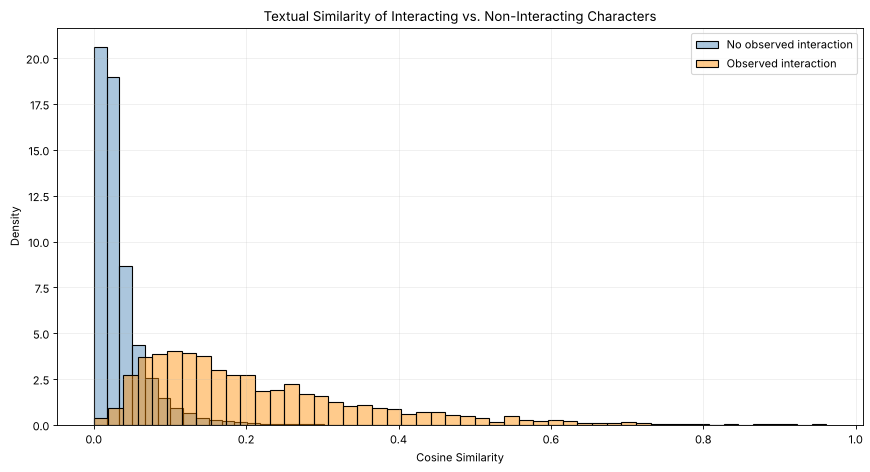

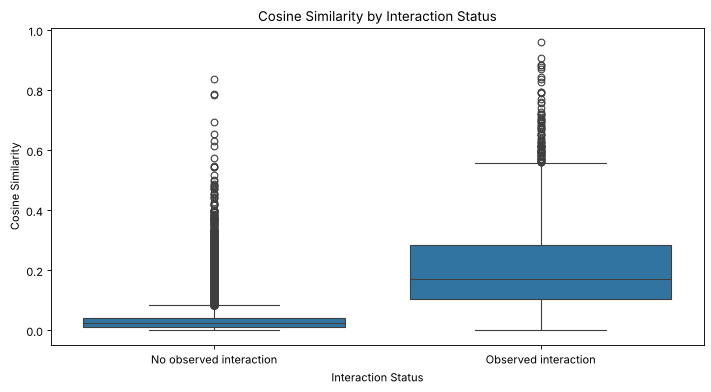

In [25]:
# 9.5. Comparing Textual Similarity Distributions

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Separate interacting and non-interacting pairs
interacting = interaction_pairs.loc[
    interaction_pairs["Interaction"] == 1,
    "Similarity"
]

non_interacting = interaction_pairs.loc[
    interaction_pairs["Interaction"] == 0,
    "Similarity"
]

# Summary statistics
summary = (
    interaction_pairs
    .groupby("Interaction")["Similarity"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .rename(index={
        0: "No observed interaction",
        1: "Observed interaction"
    })
)

print("Similarity statistics by interaction status:")
display(summary.round(6))

# Compare means
mean_difference = (
    interacting.mean() - non_interacting.mean()
)

print(
    f"\nMean similarity difference: "
    f"{mean_difference:.6f}"
)

print(
    f"Mean similarity ratio: "
    f"{interacting.mean() / non_interacting.mean():.2f}"
)

# Plot similarity distributions
plt.figure(figsize=(11, 6))

sns.histplot(
    non_interacting,
    bins=50,
    stat="density",
    color="steelblue",
    alpha=0.45,
    label="No observed interaction"
)

sns.histplot(
    interacting,
    bins=50,
    stat="density",
    color="darkorange",
    alpha=0.45,
    label="Observed interaction"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Density")
plt.title(
    "Textual Similarity of Interacting vs. Non-Interacting Characters"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Boxplot for an additional comparison
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=interaction_pairs,
    x="Interaction",
    y="Similarity",
    order=[0, 1]
)

plt.xticks(
    [0, 1],
    ["No observed interaction", "Observed interaction"]
)

plt.xlabel("Interaction Status")
plt.ylabel("Cosine Similarity")
plt.title("Cosine Similarity by Interaction Status")

plt.tight_layout()
plt.show()

### 9.6. Evaluating Textual Similarity as a Predictor of Character Interactions

Having observed that interacting character pairs tend to have higher
cosine similarity, we evaluate how well textual similarity distinguishes
observed network edges from pairs without recorded interactions.

We use two evaluation metrics:

- ROC-AUC: Measures the ability of textual similarity to rank
  interacting pairs above non-interacting pairs.
- Average Precision (AP): Summarizes precision across recall levels,
  accounting for the strong imbalance between observed edges and
  non-edges.

The baseline interaction prevalence is approximately 4.30%.

No supervised model is trained in this section. Instead, cosine
similarity is treated directly as a score for predicting observed
network connections.

Because the biographies may contain information about the same
relationships represented in the network, these results measure
retrospective link inference rather than future interaction prediction.

Total character pairs: 54285
Observed interacting pairs: 2334
Pairs without observed interactions: 51951

Predictive performance:
ROC-AUC: 0.9534
Average Precision: 0.6003
Baseline interaction prevalence: 0.0430
Average Precision / baseline prevalence: 13.96


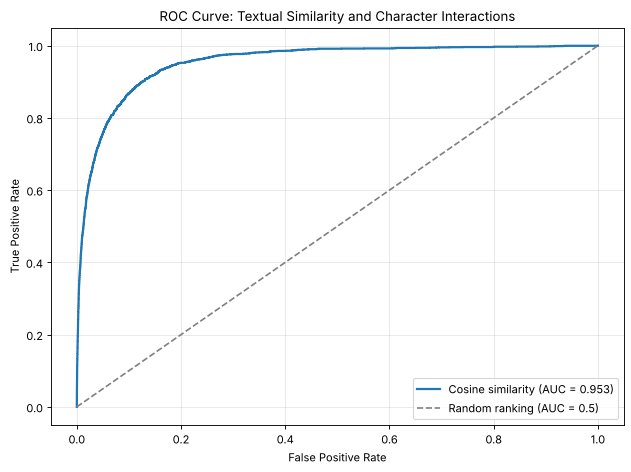

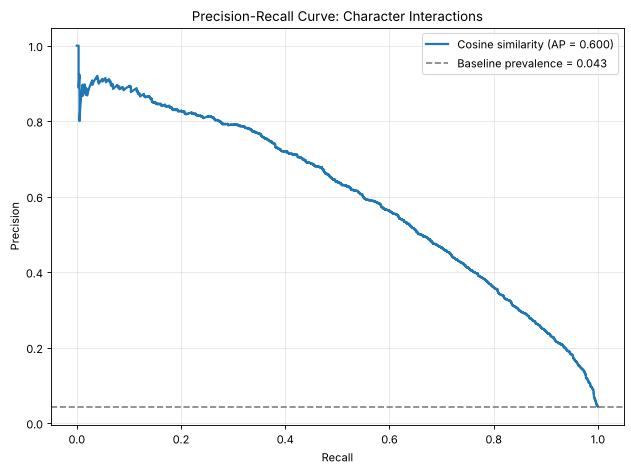


Evaluation summary:


,Metric,Value
0,ROC-AUC,0.9534
1,Average Precision,0.6003
2,Baseline prevalence,0.0430
3,AP / baseline prevalence,13.9611


In [26]:
# 9.6. Evaluating Textual Similarity as a Predictor of Interactions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve
)

# --------------------------------------------------
# 1. Prepare true labels and similarity scores
# --------------------------------------------------

y_true = interaction_pairs["Interaction"].to_numpy()
y_score = interaction_pairs["Similarity"].to_numpy()

print("Total character pairs:", len(y_true))
print("Observed interacting pairs:", y_true.sum())
print("Pairs without observed interactions:", (y_true == 0).sum())

# --------------------------------------------------
# 2. Calculate evaluation metrics
# --------------------------------------------------

roc_auc = roc_auc_score(y_true, y_score)
average_precision = average_precision_score(y_true, y_score)

baseline = y_true.mean()

print("\nPredictive performance:")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {average_precision:.4f}")
print(f"Baseline interaction prevalence: {baseline:.4f}")

print(
    f"Average Precision / baseline prevalence: "
    f"{average_precision / baseline:.2f}"
)

# --------------------------------------------------
# 3. Calculate ROC curve
# --------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    y_score
)

# --------------------------------------------------
# 4. Calculate Precision-Recall curve
# --------------------------------------------------

precision, recall, pr_thresholds = precision_recall_curve(
    y_true,
    y_score
)

# --------------------------------------------------
# 5. Plot ROC curve
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Cosine similarity (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random ranking (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Textual Similarity and Character Interactions")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Plot Precision-Recall curve
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"Cosine similarity (AP = {average_precision:.3f})"
)

plt.axhline(
    y=baseline,
    linestyle="--",
    color="gray",
    label=f"Baseline prevalence = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Character Interactions")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Summarize evaluation results
# --------------------------------------------------

evaluation_results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "Average Precision",
        "Baseline prevalence",
        "AP / baseline prevalence"
    ],
    "Value": [
        roc_auc,
        average_precision,
        baseline,
        average_precision / baseline
    ]
})

print("\nEvaluation summary:")
display(evaluation_results.round(4))

### 9.7. Null Model Comparison: Is the Association Stronger Than Chance?

In Section 9.5, we found that character pairs with observed
interactions have higher average textual similarity than pairs
without observed interactions.

To investigate whether this difference is larger than expected
by chance, we construct a simple null model.

We randomly shuffle the interaction labels across character
pairs while keeping the total number of observed interactions
unchanged. The cosine similarity scores remain fixed.

For each randomized dataset, we calculate the difference
between the mean similarity of interacting and non-interacting
pairs.

By repeating this procedure, we obtain a distribution of
differences expected under random assignment of interaction
labels.

We then compare the observed difference with this null
distribution.

This null model preserves the number of observed interactions,
but does not preserve the degree distribution of the network.

Observed results:
Mean similarity (interacting): 0.2132
Mean similarity (non-interacting): 0.0345
Observed difference: 0.1786

Null model results:
Number of randomizations: 1000
Mean null difference: 0.0000
Standard deviation: 0.0013
Empirical p-value: 0.0010


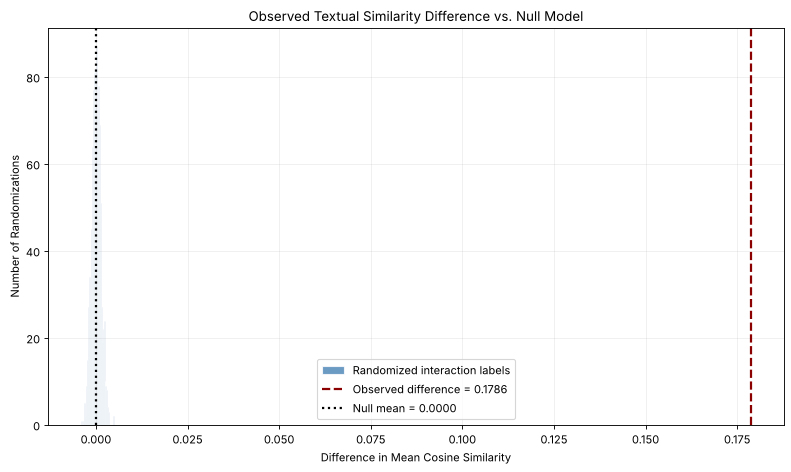


Randomizations matching or exceeding the observed difference: 0 out of 1000


In [27]:
# 9.7. Null Model Comparison

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Extract similarity scores and interaction labels
# --------------------------------------------------

similarities = interaction_pairs["Similarity"].to_numpy()
labels = interaction_pairs["Interaction"].to_numpy()

# --------------------------------------------------
# 2. Calculate the observed difference
# --------------------------------------------------

observed_mean_interacting = similarities[labels == 1].mean()
observed_mean_non_interacting = similarities[labels == 0].mean()

observed_difference = (
    observed_mean_interacting - observed_mean_non_interacting
)

print("Observed results:")
print(f"Mean similarity (interacting): {observed_mean_interacting:.4f}")
print(f"Mean similarity (non-interacting): {observed_mean_non_interacting:.4f}")
print(f"Observed difference: {observed_difference:.4f}")

# --------------------------------------------------
# 3. Generate randomized interaction labels
# --------------------------------------------------

rng = np.random.default_rng(42)

n_randomizations = 1000

null_differences = np.zeros(n_randomizations)

for i in range(n_randomizations):

    # Shuffle labels while preserving their total counts
    shuffled_labels = rng.permutation(labels)

    # Calculate mean similarity in each randomized group
    mean_interacting = similarities[shuffled_labels == 1].mean()
    mean_non_interacting = similarities[shuffled_labels == 0].mean()

    null_differences[i] = (
        mean_interacting - mean_non_interacting
    )

# --------------------------------------------------
# 4. Summarize the null distribution
# --------------------------------------------------

null_mean = null_differences.mean()
null_std = null_differences.std()

# One-sided empirical p-value
p_value = (
    np.sum(null_differences >= observed_difference) + 1
) / (n_randomizations + 1)

print("\nNull model results:")
print(f"Number of randomizations: {n_randomizations}")
print(f"Mean null difference: {null_mean:.4f}")
print(f"Standard deviation: {null_std:.4f}")
print(f"Empirical p-value: {p_value:.4f}")

# --------------------------------------------------
# 5. Visualize the null distribution
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    null_differences,
    bins=35,
    color="steelblue",
    edgecolor="white",
    alpha=0.8,
    label="Randomized interaction labels"
)

plt.axvline(
    observed_difference,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Observed difference = {observed_difference:.4f}"
)

plt.axvline(
    null_mean,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Null mean = {null_mean:.4f}"
)

plt.xlabel("Difference in Mean Cosine Similarity")
plt.ylabel("Number of Randomizations")
plt.title("Observed Textual Similarity Difference vs. Null Model")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Check how many randomizations exceed observation
# --------------------------------------------------

n_exceeding = np.sum(
    null_differences >= observed_difference
)

print(
    f"\nRandomizations matching or exceeding "
    f"the observed difference: "
    f"{n_exceeding} out of {n_randomizations}"
)

**Interpretation**

Character pairs with observed interactions have substantially higher
average textual similarity (0.2130) than pairs without recorded
interactions (0.0346), corresponding to a difference of 0.1785.

To assess whether this association could arise under random assignment
of interaction labels, we performed 1,000 randomizations while
preserving the total number of observed interactions.

The randomized differences were centered near zero (mean = 0.0000,
standard deviation = 0.0013). None of the randomizations produced
a difference as large as the observed result (empirical p = 0.0010).

These findings indicate that textual similarity is strongly associated
with observed character interactions.

However, the results should be interpreted as retrospective
identification of recorded interactions rather than prediction of
future interactions. Character biographies may explicitly describe
relationships, and the null model does not preserve the network's
degree distribution.

**Caveat.** Shuffling labels destroys the degree structure. Central characters both have many
edges and long biographies, which share many words with any other biography, so this null is
easy to beat. Section 9.8 repeats the test with a null that preserves every character's degree.

### 9.8. A Degree-Preserving Null Model

The label-shuffling null in Section 9.7 lets edges fall on any pair. In the real network,
edges concentrate on a few central characters, and those characters also have the longest
biographies. A difference in similarity could therefore come from *who has many edges*
rather than from *who interacts with whom*.

We use the same null model as in Section 6: degree-preserving rewiring (double edge swaps)
of the interaction network restricted to the characters with biographies. Every character
keeps its number of interaction partners, but the partners are randomized. If textual
similarity tracks specific interactions, the observed edges should be more similar than
the rewired ones.

In [28]:
H = G.subgraph(character_ids).copy()
H.remove_edges_from(nx.selfloop_edges(H))
char_index = {c: i for i, c in enumerate(character_ids)}

def mean_edge_similarity(graph, S):
    return np.mean([S[char_index[a], char_index[b]] for a, b in graph.edges()])

observed_edge_sim = mean_edge_similarity(H, similarity_matrix)

n_rewirings = 200
rewired_edge_sim = []
for i in range(n_rewirings):
    R = H.copy()
    nx.double_edge_swap(R, nswap=3 * R.number_of_edges(),
                        max_tries=100 * R.number_of_edges(), seed=i)
    rewired_edge_sim.append(mean_edge_similarity(R, similarity_matrix))
rewired_edge_sim = np.array(rewired_edge_sim)

p_degree_null = (1 + (rewired_edge_sim >= observed_edge_sim).sum()) / (1 + n_rewirings)
print(f"Mean similarity, observed edges: {observed_edge_sim:.4f}")
print(f"Mean similarity, degree-preserving rewired edges: "
      f"{rewired_edge_sim.mean():.4f} ± {rewired_edge_sim.std():.4f}")
print(f"Ratio observed / degree-preserving null: {observed_edge_sim / rewired_edge_sim.mean():.2f}")
print(f"Mean similarity, all pairs (label-shuffling null): {similarity_matrix[np.triu_indices(len(character_ids), 1)].mean():.4f}")
print(f"Empirical p-value: {p_degree_null:.4f}")

Mean similarity, observed edges: 0.2132
Mean similarity, degree-preserving rewired edges: 0.0919 ± 0.0014
Ratio observed / degree-preserving null: 2.32
Mean similarity, all pairs (label-shuffling null): 0.0422
Empirical p-value: 0.0050


**Interpretation.** Observed edges have a mean similarity of 0.213, against 0.092 ± 0.001 for degree-preserving rewired edges: a ratio of 2.3 (p = 0.005, the smallest value attainable with 200 rewirings). The rewired edges are already more than twice as similar as an average pair (0.042), because they still attach to the same central characters with long biographies. About 30% of the gap between edges and random pairs, (0.092 − 0.042) / (0.213 − 0.042), is therefore explained by degree alone. The rest depends on *which* characters interact, not only on how many partners they have.

### 9.9. How Much of the Similarity Is Just Names?

Wiki biographies are written from the same scenes the interaction network is built from.
When two characters share a scene, each biography names the other, and both name the
same third parties. TF-IDF gives proper names a very high weight because each name appears
in few documents. High cosine similarity can therefore mean little more than
*"these two pages mention each other"*, which is close to restating the edge.

We test this directly. We treat a word as a proper noun if it is capitalized in at least
90% of its occurrences in the corpus (and occurs at least three times). This catches
character, house and place names (Stark, Winterfell, Yoren). We then:

1. measure which share of each pair's cosine similarity comes from proper-noun terms, and
2. rebuild the TF-IDF matrix with all proper nouns removed and repeat the evaluation.

If the association survives the removal of names, the biographies share something beyond
mutual mentions: vocabulary about roles, places, events and storylines.

In [29]:
from collections import Counter
from sklearn.preprocessing import normalize

# --- 1. Identify proper nouns by capitalization in the corpus
cap_count, total_count = Counter(), Counter()
for text in df_nlp["Text"]:
    for w in re.findall(r"\b[A-Za-z]{2,}\b", text):
        total_count[w.lower()] += 1
        if w[0].isupper():
            cap_count[w.lower()] += 1

proper_nouns = {w for w, n in total_count.items()
                if n >= 3 and cap_count[w] / n >= 0.9}

terms = vectorizer.get_feature_names_out()
is_proper = np.array([t in proper_nouns for t in terms])
print(f"Vocabulary terms flagged as proper nouns: {is_proper.sum()} of {len(terms)}")

# Show the most frequent flagged terms so the rule can be checked by eye
doc_freq = np.asarray((tfidf_matrix > 0).sum(axis=0)).ravel()
print("Most widespread flagged terms:", ", ".join(terms[is_proper][np.argsort(-doc_freq[is_proper])][:40]))

# --- 2. Share of each pair's cosine similarity carried by proper-noun terms
X_dense = tfidf_matrix.toarray()
S_proper = X_dense[:, is_proper] @ X_dense[:, is_proper].T
iu = np.triu_indices(len(character_ids), 1)
sim_upper = similarity_matrix[iu]
proper_share = np.divide(S_proper[iu], sim_upper, out=np.full_like(sim_upper, np.nan), where=sim_upper > 0)

src_idx = interaction_pairs["Source"].map(char_index).to_numpy()
tgt_idx = interaction_pairs["Target"].map(char_index).to_numpy()
interaction_pairs["Proper_Share"] = (S_proper[src_idx, tgt_idx]
                                     / interaction_pairs["Similarity"].where(interaction_pairs["Similarity"] > 0))

print(f"\nMean share of cosine similarity from proper nouns, all pairs: {np.nanmean(proper_share):.2f}")
print(interaction_pairs.groupby("Interaction")["Proper_Share"].mean()
      .rename({0: "No observed interaction", 1: "Observed interaction"}).round(2))

# --- 3. TF-IDF without proper nouns
X_masked = X_dense.copy()
X_masked[:, is_proper] = 0
X_masked = normalize(X_masked)
similarity_masked = X_masked @ X_masked.T
interaction_pairs["Similarity_Masked"] = similarity_masked[src_idx, tgt_idx]

print("\nTop 10 pairs before and after removing names:")
display(interaction_pairs.nlargest(10, "Similarity")[
    ["Source", "Target", "Interaction", "Similarity", "Similarity_Masked", "Proper_Share"]].round(3))

Vocabulary terms flagged as proper nouns: 647 of 9004
Most widespread flagged terms: episode, house, lord, stark, snow, jon, lannister, winterfell, landing, ser, baratheon, tyrion, daenerys, white, targaryen, cersei, jaime, sansa, kingdoms, iron, eddard, westeros, harrenhal, robert, robb, arya, dragonstone, tywin, stannis, joffrey, valar, bran, baelor, lannisters, winds, hbo, starks, mormont, walkers, bolton

Mean share of cosine similarity from proper nouns, all pairs: 0.48
Interaction
No observed interaction    0.47
Observed interaction       0.72
Name: Proper_Share, dtype: float64

Top 10 pairs before and after removing names:


,Source,Target,Interaction,Similarity,Similarity_Masked,Proper_Share
0,BITER,RORGE,1,0.961,0.908,0.768
1,DESMOND,ELDRICK,1,0.909,0.929,0.550
2,KEGS,MULLY,1,0.886,0.876,0.244
3,GILLY,LITTLE_SAM,1,0.883,0.676,0.882
4,CRAYAH,DIRAH,1,0.879,0.799,0.665
5,MARTYN,WILLEM_LANNISTER,1,0.873,0.530,0.861
6,LITTLE_SAM,SAM,1,0.846,0.540,0.905
7,BLACK_JACK,KEGS,1,0.839,0.826,0.210
8,GARED,WAYMAR_ROYCE,0,0.839,0.740,0.713
9,COOPER,DONNEL_HILL,1,0.828,0.826,0.385


ROC-AUC  with names: 0.953   without names: 0.938
AP       with names: 0.600   without names: 0.593   (random: 0.043)
Degree-preserving null, without names: observed 0.2749 vs rewired 0.2121 ± 0.0010 (ratio 1.30, p = 0.0050)


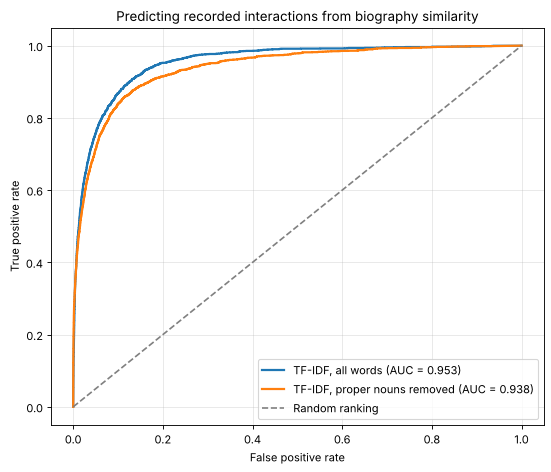

In [30]:
y_true = interaction_pairs["Interaction"].to_numpy()

masked_auc = roc_auc_score(y_true, interaction_pairs["Similarity_Masked"])
masked_ap = average_precision_score(y_true, interaction_pairs["Similarity_Masked"])

observed_edge_sim_masked = mean_edge_similarity(H, similarity_masked)
rewired_masked = []
for i in range(n_rewirings):
    R = H.copy()
    nx.double_edge_swap(R, nswap=3 * R.number_of_edges(),
                        max_tries=100 * R.number_of_edges(), seed=i)
    rewired_masked.append(mean_edge_similarity(R, similarity_masked))
rewired_masked = np.array(rewired_masked)
p_masked = (1 + (rewired_masked >= observed_edge_sim_masked).sum()) / (1 + n_rewirings)

print(f"ROC-AUC  with names: {roc_auc:.3f}   without names: {masked_auc:.3f}")
print(f"AP       with names: {average_precision:.3f}   without names: {masked_ap:.3f}   (random: {y_true.mean():.3f})")
print(f"Degree-preserving null, without names: observed {observed_edge_sim_masked:.4f} vs "
      f"rewired {rewired_masked.mean():.4f} ± {rewired_masked.std():.4f} "
      f"(ratio {observed_edge_sim_masked / rewired_masked.mean():.2f}, p = {p_masked:.4f})")

fig, ax = plt.subplots(figsize=(7, 6))
for col, label in [("Similarity", "TF-IDF, all words"),
                   ("Similarity_Masked", "TF-IDF, proper nouns removed")]:
    f, t, _ = roc_curve(y_true, interaction_pairs[col])
    ax.plot(f, t, lw=2, label=f"{label} (AUC = {roc_auc_score(y_true, interaction_pairs[col]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Predicting recorded interactions from biography similarity")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation.** Proper nouns carry 72% of the cosine similarity of interacting pairs, against 47% for non-interacting pairs, so mutual mentions are a large part of the signal. Yet removing every proper noun barely changes how well similarity ranks the pairs: ROC-AUC drops from 0.953 to 0.938 and average precision from 0.600 to 0.593 (random: 0.043). Interacting characters also share ordinary vocabulary, namely the places, objects and events of the scenes they appear in. Kegs, Mully and Black Jack Bulwer, for example, are all described visiting the same brothel. Against the degree-preserving null, the effect without names shrinks from a ratio of 2.32 to 1.30 but remains significant (p = 0.005).

What remains after masking is therefore not name matching, but it is still largely *shared scene description*: the Wiki narrates the same scenes the network counts, so the text measure is not independent of the edges. The masking rule is also somewhat aggressive. Besides names, it removes capitalized common words such as *Episode*, *House*, *Lord*, *White* and *Iron*, which makes the masked result a conservative estimate.

### 9.10. Comparison With Non-Textual Baselines

Before crediting the text, we check whether something simpler ranks the pairs just as well:

- **Biography length** (sum of log word counts): important characters have long pages and many edges.
- **Degree product** (preferential attachment): this is circular, because degree comes from the
  same network we are predicting, but it shows how much is explained by "being a central character".

We also compute the AUC of textual similarity *within* deciles of biography length. Inside a
decile, pairs have comparable page lengths, so a remaining AUC above 0.5 cannot be explained
by length alone.

In [31]:
words_by_id = df_nlp.set_index("Network_ID")["Words"]
degree_by_id = dict(G.degree())

interaction_pairs["Length_Score"] = (np.log(interaction_pairs["Source"].map(words_by_id))
                                     + np.log(interaction_pairs["Target"].map(words_by_id)))
interaction_pairs["Degree_Product"] = (interaction_pairs["Source"].map(degree_by_id)
                                       * interaction_pairs["Target"].map(degree_by_id))

scores = {
    "TF-IDF, all words": "Similarity",
    "TF-IDF, proper nouns removed": "Similarity_Masked",
    "Biography length": "Length_Score",
    "Degree product (circular)": "Degree_Product",
}
baseline_table = pd.DataFrame([
    {"Score": name,
     "ROC-AUC": roc_auc_score(y_true, interaction_pairs[col]),
     "Average precision": average_precision_score(y_true, interaction_pairs[col])}
    for name, col in scores.items()
])
print(f"Random ranking: ROC-AUC = 0.500, AP = {y_true.mean():.3f}")
display(baseline_table.round(3))

interaction_pairs["Length_Decile"] = pd.qcut(interaction_pairs["Length_Score"], 10, labels=False)
stratified = []
for d, g in interaction_pairs.groupby("Length_Decile"):
    if g["Interaction"].nunique() == 2:
        stratified.append({
            "Length decile": d + 1,
            "Pairs": len(g),
            "Edges": int(g["Interaction"].sum()),
            "AUC, all words": roc_auc_score(g["Interaction"], g["Similarity"]),
            "AUC, no names": roc_auc_score(g["Interaction"], g["Similarity_Masked"]),
        })
stratified = pd.DataFrame(stratified)
display(stratified.round(3))

Random ranking: ROC-AUC = 0.500, AP = 0.043


,Score,ROC-AUC,Average precision
0,"TF-IDF, all words",0.953,0.600
1,"TF-IDF, proper nouns removed",0.938,0.593
2,Biography length,0.875,0.405
3,Degree product (circular),0.900,0.464


,Length decile,Pairs,Edges,"AUC, all words","AUC, no names"
0,1,5429,31,0.923,0.910
1,2,5428,16,0.860,0.875
2,3,5429,23,0.944,0.935
3,4,5428,30,0.977,0.855
4,5,5429,50,0.927,0.814
5,6,5428,74,0.929,0.838
6,7,5428,119,0.920,0.809
7,8,5429,195,0.944,0.823
8,9,5428,355,0.929,0.821
9,10,5429,1441,0.896,0.851


**Interpretation.** Biography length alone reaches ROC-AUC 0.875 and the (circular) degree product 0.900. A large part of the predictive performance therefore reflects that important characters have both long pages and many interaction partners. Textual similarity still beats both baselines (0.953 with names, 0.938 without). Within deciles of biography length, its AUC stays between 0.86 and 0.98 with names and between 0.81 and 0.94 without. The text signal is therefore not an artefact of page length.

### 9.11. Do Characters Who Interact More Have More Similar Biographies?

So far an edge is binary. The network also records how often two characters interact
(the summed weight over seasons). If biography similarity reflects narrative closeness, it should
increase with interaction weight among connected pairs.

In [32]:
from scipy.stats import spearmanr

weight_lookup = {frozenset((a, b)): w for a, b, w in
                 zip(combined_edges["Source"], combined_edges["Target"], combined_edges["Weight"])}
edge_rows = interaction_pairs[interaction_pairs["Interaction"] == 1].copy()
edge_rows["Weight"] = [weight_lookup[frozenset((a, b))]
                       for a, b in zip(edge_rows["Source"], edge_rows["Target"])]

for col, label in [("Similarity", "all words"), ("Similarity_Masked", "proper nouns removed")]:
    rho, p = spearmanr(edge_rows["Weight"], edge_rows[col])
    print(f"Spearman rho, weight vs similarity ({label}): {rho:.3f} (p = {p:.2g}, n = {len(edge_rows)})")

edge_rows["Weight_Bin"] = pd.qcut(edge_rows["Weight"].rank(method="first"), 5,
                                  labels=["lowest 20%", "20-40%", "40-60%", "60-80%", "highest 20%"])
display(edge_rows.groupby("Weight_Bin", observed=True)[["Weight", "Similarity", "Similarity_Masked"]]
        .median().round(3))

Spearman rho, weight vs similarity (all words): 0.468 (p = 2.9e-127, n = 2334)
Spearman rho, weight vs similarity (proper nouns removed): 0.535 (p = 6.6e-173, n = 2334)


,Weight,Similarity,Similarity_Masked
Weight_Bin,,,
lowest 20%,2.0,0.124,0.211
20-40%,3.0,0.135,0.214
40-60%,6.0,0.144,0.237
60-80%,13.0,0.194,0.309
highest 20%,44.0,0.292,0.395


**Interpretation.** Among connected pairs, similarity increases with interaction weight (Spearman ρ = 0.47 with names, 0.53 without; n = 2,334). The median similarity without names rises from 0.21 for the weakest fifth of edges to 0.40 for the strongest fifth. Biography similarity therefore tracks not only *whether* two characters interact but *how much*, a graded relation the binary analysis could not show.

### 9.12. Do Interaction Communities Share Vocabulary?

Section 5 raised a second question: are biographies of characters in the same Louvain
community more similar than biographies of characters in different communities? We compare
the mean similarity of within-community and between-community pairs, and test the difference
against a null that permutes community labels across characters (community sizes preserved).

In [33]:
comm = np.array([community_map[c] for c in character_ids])
same_comm = (comm[:, None] == comm[None, :])[iu]

def within_minus_between(S, same):
    v = S[iu]
    return v[same].mean() - v[~same].mean()

rng = np.random.default_rng(0)
for S, label in [(similarity_matrix, "all words"), (similarity_masked, "proper nouns removed")]:
    obs = within_minus_between(S, same_comm)
    null = []
    for _ in range(1000):
        c = rng.permutation(comm)
        null.append(within_minus_between(S, (c[:, None] == c[None, :])[iu]))
    null = np.array(null)
    p = (1 + (null >= obs).sum()) / 1001
    print(f"[{label}] within {S[iu][same_comm].mean():.4f} vs between {S[iu][~same_comm].mean():.4f}; "
          f"difference {obs:.4f}, null {null.mean():.4f} ± {null.std():.4f}, p = {p:.4f}")

[all words] within 0.0906 vs between 0.0314; difference 0.0591, null 0.0000 ± 0.0010, p = 0.0010
[proper nouns removed] within 0.1017 vs between 0.0703; difference 0.0313, null -0.0001 ± 0.0021, p = 0.0010


**Interpretation.** Characters in the same Louvain community have more similar biographies than characters in different communities: 0.091 against 0.031 with names, and 0.102 against 0.070 without names. Both differences lie far outside the label-permutation null (p = 0.001). The interaction communities correspond to shared vocabulary, that is, to storylines that are also visible in the text. This null permutes community labels freely and so does not control for degree.

### 9.13. Manual Validation of Textual Similarity

Although the previous analyses show a strong association between
textual similarity and observed character interactions, high
similarity does not necessarily imply a direct relationship.

To better understand our results, we manually inspect a small
sample of character pairs.

We select pairs from three categories:

1. High textual similarity with an observed interaction.
2. High textual similarity without an observed interaction.
3. Randomly selected character pairs.

For each pair, we examine the character biographies and assess
whether the texts describe a direct relationship, a shared
storyline or context, or merely similar vocabulary.

We also compare the textual evidence with the interaction
network. A missing network edge is interpreted as an unrecorded
interaction rather than proof that no relationship exists.

This qualitative validation helps identify possible limitations
of our text-based approach and interaction dataset.

In [34]:
# 9.8. Manual Validation of Character Relationships

import pandas as pd

# --------------------------------------------------
# 1. Rank pairs by textual similarity
# --------------------------------------------------

ranked_pairs = interaction_pairs.sort_values(
    "Similarity",
    ascending=False
).reset_index(drop=True)

# --------------------------------------------------
# 2. High similarity with observed interactions
# --------------------------------------------------

high_similarity_edges = (
    ranked_pairs[ranked_pairs["Interaction"] == 1]
    .head(5)
    .copy()
)

high_similarity_edges["Category"] = (
    "High similarity - observed interaction"
)

# --------------------------------------------------
# 3. High similarity without observed interactions
# --------------------------------------------------

high_similarity_non_edges = (
    ranked_pairs[ranked_pairs["Interaction"] == 0]
    .head(5)
    .copy()
)

high_similarity_non_edges["Category"] = (
    "High similarity - no recorded interaction"
)

# --------------------------------------------------
# 4. Random character pairs
# --------------------------------------------------

random_pairs = (
    ranked_pairs
    .sort_values(["Source", "Target"])
    .sample(n=5, random_state=42)
    .copy()
)

random_pairs["Category"] = "Random pair"

# --------------------------------------------------
# 5. Combine selected pairs
# --------------------------------------------------

validation_pairs = pd.concat(
    [
        high_similarity_edges,
        high_similarity_non_edges,
        random_pairs
    ],
    ignore_index=True
)

validation_pairs = validation_pairs[
    ["Category", "Source", "Target",
     "Similarity", "Interaction"]
]

print("Character pairs selected for manual validation:")

display(validation_pairs.round(4))

Character pairs selected for manual validation:


,Category,Source,Target,Similarity,Interaction
0,High similarity - observed interaction,BITER,RORGE,0.9615,1
1,High similarity - observed interaction,DESMOND,ELDRICK,0.9088,1
2,High similarity - observed interaction,KEGS,MULLY,0.8861,1
3,High similarity - observed interaction,GILLY,LITTLE_SAM,0.8835,1
4,High similarity - observed interaction,CRAYAH,DIRAH,0.8789,1
5,High similarity - no recorded interaction,GARED,WAYMAR_ROYCE,0.8387,0
6,High similarity - no recorded interaction,GATINS,MORGAN,0.7870,0
7,High similarity - no recorded interaction,FALYSE,LOLLYS,0.7857,0
8,High similarity - no recorded interaction,COHOLLO,QOTHO,0.6935,0
9,High similarity - no recorded interaction,FALYSE,TANDA,0.6548,0


In [35]:
# 9.8. Record All Manual Validation Findings

# --------------------------------------------------
# 1. Define manually examined character relationships
# --------------------------------------------------

manual_findings = {

    ("BITER", "RORGE"): (
        "Direct relationship",
        "Biter and Rorge were imprisoned together and "
        "recruited into the Night's Watch by Yoren.",
        "Consistent with recorded network edge"
    ),

    ("DESMOND", "ELDRICK"): (
        "Direct shared scene",
        "Desmond and Eldrick walk together through the "
        "Red Keep gardens and laugh at Tyrion.",
        "Consistent with recorded network edge"
    ),

    ("GARED", "WAYMAR_ROYCE"): (
        "Shared journey",
        "Gared and Waymar Royce travel together on a "
        "Night's Watch ranging beyond the Wall.",
        "Shared journey without recorded network edge"
    ),

    ("FALYSE", "LOLLYS"): (
        "Family relationship",
        "Falyse and Lollys are sisters. Their biographies "
        "describe their family connection and Bronn's "
        "arranged marriage to Lollys.",
        "Family relationship without recorded network edge"
    ),

    ("GATINS", "MORGAN"): (
        "Direct shared scene",
        "Gatins and Morgan confront Ray's group together "
        "while requesting food and supplies.",
        "Shared scene without recorded network edge"
    ),

    ("COHOLLO", "QOTHO"): (
        "Direct shared scene",
        "Cohollo and Qotho accompany Khal Drogo "
        "to meet Daenerys Targaryen.",
        "Shared scene without recorded network edge"
    ),

    ("FALYSE", "TANDA"): (
        "Family relationship",
        "Tanda is Falyse's mother. Falyse is expected "
        "to inherit Castle Stokeworth after Tanda's death.",
        "Family relationship without recorded network edge"
    ),

    ("MYRCELLA", "TOMMEN"): (
        "Family relationship",
        "Myrcella and Tommen are siblings, as explicitly "
        "stated in Myrcella's biography.",
        "Consistent with recorded network edge"
    )
}

# --------------------------------------------------
# 2. Create or reset manual validation columns
# --------------------------------------------------

manual_validation = validation_pairs.copy()

manual_validation["Relationship_Evidence"] = ""
manual_validation["Evidence_Notes"] = ""
manual_validation["Network_Agreement"] = ""

# --------------------------------------------------
# 3. Add all manually verified findings
# --------------------------------------------------

for (source, target), findings in manual_findings.items():

    mask = (
        (
            (manual_validation["Source"] == source) &
            (manual_validation["Target"] == target)
        )
        |
        (
            (manual_validation["Source"] == target) &
            (manual_validation["Target"] == source)
        )
    )

    manual_validation.loc[
        mask,
        [
            "Relationship_Evidence",
            "Evidence_Notes",
            "Network_Agreement"
        ]
    ] = list(findings)

# --------------------------------------------------
# 4. Display completed manual validation findings
# --------------------------------------------------

validated_pairs = manual_validation[
    manual_validation["Relationship_Evidence"] != ""
].copy()

print("Manually validated character pairs:")
display(validated_pairs.round(4))

# --------------------------------------------------
# 5. Summarize validation results
# --------------------------------------------------

print("\nManual validation summary:")
print(f"Pairs manually examined: {len(validated_pairs)}")

print(
    "Pairs with recorded network interactions:",
    int(validated_pairs["Interaction"].sum())
)

print(
    "Pairs without recorded network interactions:",
    int((validated_pairs["Interaction"] == 0).sum())
)

print(
    "Remaining pairs awaiting validation:",
    len(manual_validation) - len(validated_pairs)
)

Manually validated character pairs:


,Category,Source,Target,Similarity,Interaction,Relationship_Evidence,Evidence_Notes,Network_Agreement
0,High similarity - observed interaction,BITER,RORGE,0.9615,1,Direct relationship,Biter and Rorge were imprisoned together and recruited into the Night's Watch by Yoren.,Consistent with recorded network edge
1,High similarity - observed interaction,DESMOND,ELDRICK,0.9088,1,Direct shared scene,Desmond and Eldrick walk together through the Red Keep gardens and laugh at Tyrion.,Consistent with recorded network edge
5,High similarity - no recorded interaction,GARED,WAYMAR_ROYCE,0.8387,0,Shared journey,Gared and Waymar Royce travel together on a Night's Watch ranging beyond the Wall.,Shared journey without recorded network edge
6,High similarity - no recorded interaction,GATINS,MORGAN,0.7870,0,Direct shared scene,Gatins and Morgan confront Ray's group together while requesting food and supplies.,Shared scene without recorded network edge
7,High similarity - no recorded interaction,FALYSE,LOLLYS,0.7857,0,Family relationship,Falyse and Lollys are sisters. Their biographies describe their family connection and Bronn's arranged marriage to Lollys.,Family relationship without recorded network edge
8,High similarity - no recorded interaction,COHOLLO,QOTHO,0.6935,0,Direct shared scene,Cohollo and Qotho accompany Khal Drogo to meet Daenerys Targaryen.,Shared scene without recorded network edge
9,High similarity - no recorded interaction,FALYSE,TANDA,0.6548,0,Family relationship,Tanda is Falyse's mother. Falyse is expected to inherit Castle Stokeworth after Tanda's death.,Family relationship without recorded network edge



Manual validation summary:
Pairs manually examined: 7
Pairs with recorded network interactions: 2
Pairs without recorded network interactions: 5
Remaining pairs awaiting validation: 8


### 9.14. A Hand-Labeled Validation Sample

The eight pairs above illustrate the method but are too few to estimate an error rate.
We therefore draw a stratified sample of 50 pairs, using the similarity **without names**:

- 20 pairs with the highest similarity and a recorded edge,
- 20 pairs with the highest similarity and **no** recorded edge,
- 10 random pairs with no recorded edge (control).

For each pair, the sheet lists the sentences in either biography that mention the other
character, which makes labeling quicker. **Two group members label every pair
independently**, without looking at the similarity score, using one of:

- `direct`: the characters share a scene or speak to each other,
- `indirect`: same storyline, place or family, but no shared scene,
- `none`: no meaningful narrative connection.

We then report Cohen's kappa between the two annotators and, for each stratum, the share
of pairs with a real relationship. The share of `direct` pairs among high-similarity
non-edges estimates how many interactions the network misses.

In [36]:
def name_tokens(title):
    stop = {"the", "of", "and", "ser", "lord", "lady", "king", "queen", "maester", "septa", "high", "old", "little", "black"}
    return [t for t in re.findall(r"[A-Za-z']+", title) if len(t) > 2 and t.lower() not in stop]

title_by_id = df_nlp.set_index("Network_ID")["Wiki_Title"]
text_by_id = df_nlp.set_index("Network_ID")["Text"]

def mentions(a, b, max_sentences=2):
    pattern = r"\b(" + "|".join(map(re.escape, name_tokens(title_by_id[b]))) + r")\b"
    sentences = re.split(r"(?<=[.!?])\s+", text_by_id[a])
    hits = [s for s in sentences if re.search(pattern, s)]
    return " | ".join(hits[:max_sentences])

ranked = interaction_pairs.sort_values("Similarity_Masked", ascending=False)
sample = pd.concat([
    ranked[ranked["Interaction"] == 1].head(20).assign(Stratum="high similarity, edge"),
    ranked[ranked["Interaction"] == 0].head(20).assign(Stratum="high similarity, no edge"),
    interaction_pairs[interaction_pairs["Interaction"] == 0].sample(10, random_state=1)
        .assign(Stratum="random, no edge"),
], ignore_index=True)

sample["A_mentions_B"] = [mentions(a, b) for a, b in zip(sample["Source"], sample["Target"])]
sample["B_mentions_A"] = [mentions(b, a) for a, b in zip(sample["Source"], sample["Target"])]
sample["Label_Annotator1"] = ""
sample["Label_Annotator2"] = ""

label_file = Path("hand_labels.csv")
if not label_file.exists():
    sample[["Stratum", "Source", "Target", "A_mentions_B", "B_mentions_A",
            "Label_Annotator1", "Label_Annotator2"]].to_csv(label_file, index=False)
    print(f"Wrote {label_file}: fill in the two label columns and re-run the next cell.")
else:
    print(f"{label_file} already exists; it was not overwritten.")
display(sample[["Stratum", "Source", "Target", "Similarity_Masked", "A_mentions_B"]].head(10))

hand_labels.csv already exists; it was not overwritten.


,Stratum,Source,Target,Similarity_Masked,A_mentions_B
0,"high similarity, edge",DESMOND,ELDRICK,0.929289,"As Tyrion and Sansa walk through the Red Keep 's gardens, Lord Desmond and Ser Eldrick Sarsfield walk by, clearly laughing at Tyrion, who notes their names for future humiliation."
1,"high similarity, edge",BITER,RORGE,0.908078,"Along with Rorge and Jaqen H'ghar , he was fished out of the dungeons by Yoren and forcibly recruited into the Night's Watch . | He chooses murderer Biter as a potential candidate, as well as two other criminals (Jaqen H'ghar and Rorge) from the black cells, where the worst criminals are kept."
2,"high similarity, edge",KEGS,MULLY,0.875606,"Along with Black Jack Bulwer and Mully , he travels to the brothel in Mole's Town ."
3,"high similarity, edge",BLACK_JACK,KEGS,0.826494,"Along with Kegs and Mully , he travels to the brothel in Mole's Town ."
4,"high similarity, edge",COOPER,DONNEL_HILL,0.826323,"When Castle Black's inner gate is threatened by the giant Mag Mar Tun Doh Weg , he accompanies Grenn , Donnel Hill , and other three black brothers to defend it."
5,"high similarity, edge",CRAYAH,DIRAH,0.799305,"Along with Marei and Dirah , Craya is hired by Bronn . | As Marei mounts Bronn, Craya tells Dirah that a soldier named Eddie survived the battle but returned to King's Landing with his face burned off, leaving him without eyelids, to which Dirah asks how he sleeps without eyelids."
6,"high similarity, edge",HOT_PIE,LOMMY_GREENHANDS,0.787985,"Hot Pie and Lommy Greenhands are recruited to join the Night's Watch . | Later, Arya, Hot Pie and Lommy Greenhands wash cook pots in the stream while Gendry fills a pail with water."
7,"high similarity, edge",BLACK_JACK,MULLY,0.750438,"Along with Kegs and Mully , he travels to the brothel in Mole's Town ."
8,"high similarity, edge",GILLY,LITTLE_SAM,0.676255,Gilly notes Sam's courage and asks him to take her away. | Sam spots Gilly carrying out her chores as he is preparing to leave and approaches her.
9,"high similarity, edge",DONGO_THE_GIANT,MAG_THE_MIGHTY,0.675194,"He escorts Mag Mar Tun Doh Weg and his mammoth to the outer gate of the Wall . | At the gate, while Mag turns around the mammoth and several wildlings tie ropes to it, Dongo violently exposes the gate's supports and ties the other end of the ropes to them."


In [37]:
from sklearn.metrics import cohen_kappa_score

labels_df = pd.read_csv("hand_labels.csv").fillna("")
done = labels_df[(labels_df["Label_Annotator1"] != "") & (labels_df["Label_Annotator2"] != "")]

if len(done) == 0:
    print("No labels yet: fill in Label_Annotator1 and Label_Annotator2 in hand_labels.csv.")
else:
    kappa = cohen_kappa_score(done["Label_Annotator1"], done["Label_Annotator2"])
    print(f"Pairs labeled by both annotators: {len(done)} of {len(labels_df)}")
    print(f"Cohen's kappa between annotators: {kappa:.2f}")
    agreed = done[done["Label_Annotator1"] == done["Label_Annotator2"]]
    print(f"Pairs where annotators agree: {len(agreed)}")
    display(pd.crosstab(agreed["Stratum"], agreed["Label_Annotator1"], normalize="index").round(2))

Pairs labeled by both annotators: 50 of 50
Cohen's kappa between annotators: 0.54
Pairs where annotators agree: 35


Label_Annotator1,direct,indirect,none
Stratum,,,
"high similarity, edge",1.00,0.00,0.00
"high similarity, no edge",0.29,0.29,0.43
"random, no edge",0.00,0.00,1.00


**Interpretation.** The two annotators agree on 35 of the 50 pairs, with Cohen's κ = 0.54 (moderate agreement). Most disagreements (8 of 15) are pairs that one annotator labeled `indirect` and the other `direct`. One annotator judged mainly from the quoted sentences, the other from knowledge of the series, so siblings such as Cersei and Jaime were labeled `indirect` by the first and `direct` by the second.

- **High similarity, edge:** 19 of the 20 pairs are labeled as related by both annotators, which confirms that the top of the ranking is meaningful.
- **High similarity, no edge:** both annotators agree that 4 of the 20 pairs share a scene (Gared and Waymar Royce, Gatins and Morgan, Cohollo and Qotho, Shagga and Timett) and that 4 more are related without a shared scene. Taken separately, the annotators label 5 and 7 of these pairs as `direct`. Roughly a quarter to a third of the most similar non-edges are therefore interactions the network does not record.
- **Random, no edge:** neither annotator found a shared scene in any of the 10 random pairs.

## 10. Discussion and Limitations

### 10.1. Does Textual Similarity Identify Character Interactions?

Yes, and more robustly than our first analysis could show. Recorded interactions have a mean cosine similarity of 0.213, against 0.035 for pairs without a recorded interaction. Similarity ranks the pairs with ROC-AUC 0.953 and average precision 0.600, about 14 times the 4.3% prevalence of edges.

The simple label-shuffling null overstates this effect, because it ignores that edges concentrate on central characters with long biographies. Against a degree-preserving null, observed edges are 2.3 times more similar than rewired edges (p = 0.005). Biography length alone already reaches AUC 0.875, but textual similarity beats it, including within deciles of biography length.

### 10.2. What Does Textual Similarity Capture?

The most obvious explanation is that biographies simply name each other, and it explains part of the signal: proper nouns carry 72% of the similarity of interacting pairs. Removing every proper noun, however, leaves AUC at 0.938 and the degree-preserving effect significant (ratio 1.30, p = 0.005). What remains is shared description of the same scenes: the same places, objects and events.

Two further results support this reading. Similarity increases with how often two characters interact (Spearman ρ = 0.53 without names), and characters in the same interaction community have more similar biographies than characters in different communities (p = 0.001).

The pairs with high similarity but no recorded edge are informative. Gared and Waymar Royce travel together on a ranging, Cohollo and Qotho accompany Khal Drogo together, and Gatins and Morgan confront Ray's group together. These are shared scenes that the interaction network does not record. Falyse, Lollys and Tanda are related through family rather than through scenes. The hand-labeled sample (Section 9.14) quantifies how often this happens.

### 10.3. Limitations

**The text is not independent of the network.** The Wiki biographies narrate the same scenes from which the interactions are derived. Our results therefore measure how consistently two descriptions of the same series agree; they are not a prediction of unseen relationships.

**Incomplete interaction representation.** The interaction network follows its own edge-definition criteria. An absent edge does not mean that two characters never interacted, and our validation finds pairs who share scenes without a recorded edge.

**Coverage.** Seven pages also narrate the prequel *House of the Dragon*; we removed those sections (Section 8.7), which leaves Gerard and Rhaenyra with almost no text. Only the 330 characters with a curated Wiki mapping are analyzed (88.5% of the edges). The excluded characters are mostly minor or generic roles.

**Textual representation.** TF-IDF ignores word order and context. Our proper-noun filter is a capitalization rule: it also removes some capitalized common words (*House*, *Lord*, *White*), and it may miss names that are often written in lowercase.

**Null models.** The degree-preserving null keeps each character's number of partners but not the interaction weights or the community structure. The community comparison uses a label-permutation null that does not control for degree.

**Manual validation.** Section 9.13 illustrates individual pairs. The error rates come from the stratified 50-pair sample labeled independently by two group members (Section 9.14).

### 10.4. Overall Conclusion

Biography similarity identifies recorded interactions in Game of Thrones well beyond what character prominence or mutual name mentions explain. It also grows with interaction strength and with shared community membership. Because the Wiki and the interaction network describe the same scenes, this is best read as agreement between two separately compiled records of the same story, not as prediction. The disagreements between them point to interactions that the network misses.